# RAVE-VL v4 · Portion 7 — full evaluation, final tables and paper figures (CPU only, no A100 time)

Reads every result Portions 2–6 left in Google Drive (`MyDrive/Koushik 2/rave_work/`) and recomputes **all metrics with
one code path**, so every number in the paper has the same definition. Run it on a free CPU runtime. Missing portions
are skipped.

| Experiment | Data | Model | Gates |
|---|---|---|---|
| main | MMMU-Pro standard-10 (1,730) | Qwen3-VL-8B | **pre-registered** Portion-2 scores and plan (hash-checked) |
| replication | MMMU-Pro standard-10 | Qwen3-VL-4B | re-fitted out-of-fold |
| vision | MMMU-Pro vision (1,730 screenshots) | 8B | re-fitted + transferred unchanged |
| safeguard | HallusionBench image split (951) | 8B | re-fitted |
| fine detail | V*Bench (191), HR-Bench 4K / 8K (800 each) | 8B | re-fitted |

**Metric suite.** Accuracy with 95% bootstrap CIs; paired differences with one-sided bootstrap p, exact McNemar, Holm
(H1–H4), Cohen's h; visual tokens per question (no KV reuse and with prefix caching), compute ms, GPU energy, measured
batch-1 latency; **iso-accuracy token savings** against the uniform-resolution frontier, accuracy above that frontier at
equal tokens (H7), normalised area under each gate's accuracy–token path (AUAC), Pareto front; gate AUROC (CI), AUPRC,
AURC, **E-AURC**, selective risk at 80% coverage, Brier, ECE, calibration slope/intercept, escalation precision/recall,
rescue recall, harm exposure, **oracle efficiency**; rescued vs harmed answers per escalation input; final-answer ECE /
NLL / Brier; HallusionBench aAcc / fAcc / qAcc; HR-Bench circular accuracy; per-category and per-down-scaling
breakdowns; compute (CPU-h, GPU-h, kWh, CO₂e); pre-registration integrity.

**Outputs** → `rave_work/paper/` (CSV + LaTeX booktabs, `results_final.json`) and `rave_work/figures/fig_final_*`.

In [17]:
%pip install -q pandas pyarrow scikit-learn scipy matplotlib psutil tqdm nvidia-ml-py

⏱ cell 15: %pip install -q pandas pyarrow scikit-learn scipy matplotlib | wall 23.78 s | CPU 16.59 s (0.7 cores, sys 95.8%) | GPU 0.00 s (no GPU used) | RAM peak 10 GB


In [2]:
import os, sys, json, math, re, time, random, string, hashlib, zlib, warnings, shutil, tarfile
from pathlib import Path
import multiprocessing as mp
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

def usable_cpus():
    """CPUs this process may really use (affinity + cgroup quota). os.cpu_count() inside a container often
    reports every host core, which oversubscribes threads and makes CPU work crawl."""
    n = len(os.sched_getaffinity(0)) if hasattr(os, "sched_getaffinity") else (os.cpu_count() or 1)
    try:                                                            # cgroup v2
        q, p = open("/sys/fs/cgroup/cpu.max").read().split()[:2]
        if q != "max":
            n = min(n, max(1, int(q) // int(p)))
    except Exception:
        try:                                                        # cgroup v1
            q = int(open("/sys/fs/cgroup/cpu/cpu.cfs_quota_us").read())
            p = int(open("/sys/fs/cgroup/cpu/cpu.cfs_period_us").read())
            if q > 0:
                n = min(n, max(1, q // p))
        except Exception:
            pass
    return max(1, n)

N_CPU = int(os.environ.get("RAVE_CPUS", usable_cpus()))
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ.setdefault(_v, str(N_CPU))
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")
# fewer "out of memory" errors from fragmentation when batch shapes vary (must be set before torch is imported)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

# ── Storage: fast local working copy + permanent copy in Google Drive ("Koushik 2") ─────────────
# Colab's /content disk is wiped whenever the runtime is recycled (new GPU, disconnect, restart of the VM), so
# every portion works on local disk for speed and mirrors everything to Drive after every phase. The next
# portion restores from Drive automatically, on any runtime.
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
DRIVE_FOLDER = os.environ.get("RAVE_DRIVE_FOLDER", "Koushik 2")
if os.environ.get("RAVE_DRIVE_ROOT"):                 # any folder can stand in for Drive (tests, other machines)
    DRIVE_ROOT = Path(os.environ["RAVE_DRIVE_ROOT"]) / DRIVE_FOLDER
elif IN_COLAB:
    DRIVE_HELP = """Google Drive did not mount ({err}).
How to fix it (most common cause first):
  1. Run this cell again. In the Google sign-in window pick the SAME account that runs this notebook and tick EVERY
     permission box (in particular "See, edit, create and delete all of your Google Drive files"), then Continue.
  2. Or: folder icon in Colab's left sidebar -> "Mount Drive" (mounts without the pop-up), then run this cell again.
  3. Still failing: Runtime -> Disconnect and delete runtime, allow pop-ups for colab.research.google.com, start again.
Nothing has been computed yet, so nothing is lost."""

    def _mount_drive():
        if os.path.isdir("/content/drive/MyDrive"):
            return
        from google.colab import drive
        err = None
        for kw in ({}, {"force_remount": True}):          # second try = a fresh sign-in window
            try:
                drive.mount("/content/drive", timeout_ms=300_000, **kw)
            except Exception as e:                       # e.g. "credential propagation was unsuccessful"
                err = e
                print(f"  Drive mount attempt failed: {type(e).__name__}: {e}")
            if os.path.isdir("/content/drive/MyDrive"):
                return
        raise RuntimeError(DRIVE_HELP.format(err=f"{type(err).__name__}: {err}" if err else "MyDrive not visible"))

    _mount_drive()
    DRIVE_ROOT = Path("/content/drive/MyDrive") / DRIVE_FOLDER
else:
    DRIVE_ROOT = None
if DRIVE_ROOT is not None:
    DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
DRIVE_WORK = DRIVE_ROOT / "rave_work" if DRIVE_ROOT is not None else None
WORK = Path(os.environ.get("RAVE_WORK", "/content/rave_work" if IN_COLAB else "./rave_work")).resolve()
DIRS = {k: WORK / k for k in ["raw", "global", "crops", "meta", "logs", "preds"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)
HEAVY_DIRS = {"raw", "global", "crops"}               # thousands of images -> stored on Drive as one tar per dataset

def _walk_small(root):
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames[:] = [d for d in dirnames if d not in HEAVY_DIRS]
        for f in filenames:
            if f == "images.tar" or f.endswith(".partial"):
                continue
            yield Path(dirpath) / f

import threading
_SYNC_LOCK = threading.Lock()
_SYNCED = {}                                           # local path -> (size, mtime_ns) already on Drive

def _key(st):
    return (st.st_size, st.st_mtime_ns)

def sync_to_drive(quiet=True):
    """Copy every new/changed small file (tables, predictions, logs, figures) from WORK to Drive.
    Files already copied are remembered, so Drive (slow to query) is only touched for real changes; each copy goes
    to '<name>.partial' first and is then renamed, so a runtime that dies mid-copy never leaves a broken file."""
    if DRIVE_WORK is None:
        return 0
    n = 0
    with _SYNC_LOCK:
        for p in _walk_small(WORK):
            try:
                st = p.stat()
                if _SYNCED.get(p) == _key(st):
                    continue
                q = DRIVE_WORK / p.relative_to(WORK)
                try:
                    qs = q.stat()
                    if qs.st_size == st.st_size and qs.st_mtime >= st.st_mtime - 2:
                        _SYNCED[p] = _key(st)
                        continue
                except FileNotFoundError:
                    pass
                q.parent.mkdir(parents=True, exist_ok=True)
                tmp = q.with_name(q.name + ".partial")
                shutil.copyfile(p, tmp)
                try:
                    shutil.copystat(p, tmp)                # keeps mtimes when the Drive mount allows it
                except OSError:
                    pass
                os.replace(tmp, q)
                _SYNCED[p] = _key(st)
                n += 1
            except OSError as e:                           # a Drive hiccup must never kill a GPU run
                print(f"  (Drive sync skipped {p.name}: {e})")
    if not quiet:
        print(f"Drive sync: {n} file(s) -> {DRIVE_WORK}")
    return n

def sync_in_background():
    """Non-blocking sync for use inside GPU loops (skipped if a sync is already running)."""
    if DRIVE_WORK is None or _SYNC_LOCK.locked():
        return
    threading.Thread(target=lambda: sync_to_drive(), daemon=True).start()

def archive_images_to_drive(sub="", dirs=None):
    """Pack raw/, global/, crops/ of WORK/sub into one tar on Drive (thousands of small files are slow on Drive).
    dirs: which of them to keep (e.g. {"global", "crops"} when the originals can be downloaded again)."""
    if DRIVE_WORK is None:
        return
    base, dst = WORK / sub, DRIVE_WORK / sub / "images.tar"
    dst.parent.mkdir(parents=True, exist_ok=True)
    part = dst.with_name("images.tar.partial")
    with tarfile.open(part, "w") as tf:
        for d in sorted(dirs or HEAVY_DIRS):
            if (base / d).exists():
                tf.add(base / d, arcname=d)
    os.replace(part, dst)
    print(f"images archived -> {dst} ({dst.stat().st_size / 1e9:.2f} GB)")

def restore_from_drive(sub="", images=True):
    """Bring WORK/sub back from Drive on a fresh runtime: small files copied, images extracted from the tar."""
    if DRIVE_WORK is None:
        print("no Drive folder configured: using local files only"); return
    src = DRIVE_WORK / sub
    if not src.exists():
        print(f"nothing on Drive yet at {src}"); return
    n = 0
    for p in _walk_small(src):
        q = WORK / p.relative_to(DRIVE_WORK)
        if p.name == "time_ledger.jsonl" and q.exists():   # merge: Drive history + rows this runtime already wrote
            drive_text = p.read_text()
            seen = set(drive_text.splitlines())
            local_new = [l for l in q.read_text().splitlines() if l and l not in seen]
            q.write_text(drive_text + ("" if drive_text.endswith("\n") or not drive_text else "\n")
                         + "".join(l + "\n" for l in local_new))
            n += 1
            continue
        if not q.exists() or q.stat().st_size != p.stat().st_size:
            q.parent.mkdir(parents=True, exist_ok=True); shutil.copy2(p, q); n += 1
        _SYNCED[q] = _key(q.stat())                    # identical to Drive: the next sync skips it
    tar, gdir = src / "images.tar", WORK / sub / "global"
    extracted = False
    if images and tar.exists() and not (gdir.exists() and any(gdir.iterdir())):
        with tarfile.open(tar) as tf:
            try:
                tf.extractall(WORK / sub, filter="data")
            except TypeError:                          # Python < 3.12
                tf.extractall(WORK / sub)
        extracted = True
    print(f"restored {n} file(s) from {src}" + (" + images" if extracted else ""))

def save_notebook_copy(name):
    """Colab only: write this notebook WITH its outputs into Drive/<folder>/notebooks/."""
    if not IN_COLAB or DRIVE_ROOT is None:
        print("not running in Colab: save the notebook yourself"); return
    try:
        from google.colab import _message
        nb = _message.blocking_request("get_ipynb", timeout_sec=120)["ipynb"]
        out = DRIVE_ROOT / "notebooks" / f"{name}_executed_{time.strftime('%Y%m%d_%H%M')}.ipynb"
        out.parent.mkdir(parents=True, exist_ok=True)
        out.write_text(json.dumps(nb))
        print("notebook with outputs ->", out)
    except Exception as e:
        print(f"could not save the notebook automatically ({e}); use File > Save a copy in Drive")

SEED = 20261017
random.seed(SEED)
SMOKE_N = int(os.environ.get("RAVE_SMOKE_N", "0"))       # 0 = full run (1,730 questions); >0 = quick test

DATASET, CONFIG = "MMMU/MMMU_Pro", "standard (10 options)"
MODEL_ID = os.environ.get("RAVE_MODEL_ID", "Qwen/Qwen3-VL-8B-Instruct")

# Qwen3-VL geometry: 16-px patches + 2x2 spatial merge -> 1 LLM visual token per 32x32 px.
FACTOR = 32
PX_PER_TOKEN = FACTOR * FACTOR
MIN_IMG_TOKENS = 64                      # Qwen3-VL default floor (shortest_edge = 65,536 px)
GLOBAL_BUDGETS = [128, 256, 512, 1024]   # Stage-1 visual tokens per QUESTION -> uniform-resolution frontier
NATIVE_CAP = 4096                        # "native" reference: only downscaled above 4,096 tokens per question
BASES = [str(b) for b in GLOBAL_BUDGETS] + ["native"]
MAIN_BASE = "256"                        # pre-registered Stage-1 budget (P1.3 prints the label-free reason)
PROTOCOL_BASE = "1024"                   # v1 protocol budget, kept as the secondary operating point
CROP_TOKENS_MIN, CROP_TOKENS_MAX = 256, 512   # one escalation crop; small regions are up-sampled (= the zoom)
LETTERS = string.ascii_uppercase         # MMMU-Pro standard(10) has 2-12 options (one question has 12)
PH = re.compile(r"<image (\d+)>")
INSTR = "Answer with the option's letter from the given choices directly."
PROMPT_VERSION = "v2-prefix-compatible"
print(f"WORK={WORK} | Drive={DRIVE_WORK} | usable CPUs={N_CPU} (os.cpu_count()={os.cpu_count()}) | "
      f"model={MODEL_ID} | SMOKE_N={SMOKE_N or 'full run'}")

NOTEBOOK = "P7"
DEVICE, ON_GPU = "cpu", False
MAX_OPT = 12
COST_FILE = DIRS["logs"] / "variant_costs.json"
CO2_KG_PER_KWH = float(os.environ.get("RAVE_CO2_KG_PER_KWH", "0.40"))   # grid carbon intensity for the CO2e estimate
GPU_BOARD_W = 400.0                     # A100 SXM board power, used only where the NVML energy counter is missing
PAPER = WORK / "paper"
PAPER.mkdir(parents=True, exist_ok=True)

def _sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

Mounted at /content/drive
WORK=/content/rave_work | Drive=/content/drive/MyDrive/Koushik 2/rave_work | usable CPUs=2 (os.cpu_count()=2) | model=Qwen/Qwen3-VL-8B-Instruct | SMOKE_N=full run


In [3]:
# ── CPU + GPU time ledger: EVERY executed cell and every named phase gets one row ─────────────
#  cpu_s        CPU-seconds of this kernel + its worker processes (Pool / DataLoader workers)
#  cores_used   cpu_s / wall_s   (how many cores the step really kept busy)
#  gpu_busy_s   phase rows: sum of CUDA-event-timed forward passes (exact)
#               cell rows : integral of NVML GPU utilisation, sampled every 0.25 s (approximate)
#               0.00 + "none" when no GPU is used (e.g. the whole of Portion 1)
#  gpu_energy_J NVML board-energy counter difference (supported on A100)
import time, json, resource, threading, datetime as dt
import psutil

LEDGER = DIRS["logs"] / "time_ledger.jsonl"
WINDOW_FILE = DIRS["logs"] / "a100_window.json"
WINDOW_H = 7.0

def _nvml():
    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            import pynvml                        # provided by nvidia-ml-py
        pynvml.nvmlInit()
        cvd = os.environ.get("CUDA_VISIBLE_DEVICES", "0").split(",")[0].strip()
        h = pynvml.nvmlDeviceGetHandleByIndex(int(cvd) if cvd.isdigit() else 0)
        name = pynvml.nvmlDeviceGetName(h)
        return pynvml, h, (name.decode() if isinstance(name, bytes) else name)
    except Exception:
        return None, None, None
NV, NVH, GPU_NAME = _nvml()

def _energy_mJ():
    if NVH is None:
        return None
    try:
        return NV.nvmlDeviceGetTotalEnergyConsumption(NVH)
    except Exception:
        return None

def _torch_cuda():
    t = sys.modules.get("torch")
    try:
        return t if (t is not None and t.cuda.is_available() and t.cuda.is_initialized()) else None
    except Exception:
        return None

def _reaped_child_cpu():
    r = resource.getrusage(resource.RUSAGE_CHILDREN)
    return r.ru_utime + r.ru_stime

def _alive_children():
    out = {}
    try:
        for c in psutil.Process().children(recursive=True):
            try:
                t = c.cpu_times(); out[c.pid] = t.user + t.system
            except psutil.Error:
                pass
    except psutil.Error:
        pass
    return out

GPU_NOTEBOOKS = {"P2", "P3", "P4", "P5", "P6"}           # P1 and P7 run before / after the A100 window

def _ledger_window_s():
    s = 0.0
    if LEDGER.exists():
        with open(LEDGER) as f:
            for line in f:
                try:
                    r = json.loads(line)
                except ValueError:
                    continue
                if r.get("kind") == "cell" and r.get("notebook") in GPU_NOTEBOOKS and r.get("counts_to_window", True):
                    s += float(r.get("wall_s") or 0)
    return s

def window_used_h():
    """A100 hours used = executed cell time of all GPU portions (P2-P4), summed across runtimes (the ledger lives
    on Drive). Weight downloads are excluded. Idle time between cells is not counted."""
    if globals().get("NOTEBOOK") not in GPU_NOTEBOOKS:
        return None
    s = _ledger_window_s()
    ct = globals().get("CELL_TIMER")
    if ct is not None and ct.m is not None and getattr(ct, "counts", True):
        s += time.perf_counter() - ct.m.t0
    return round(s / 3600, 3)

def window(tag=""):
    used = window_used_h()
    if used is None:
        print(f"⏱ A100 time {tag}: not counted in this portion"); return
    print(f"⏱ A100 time {tag}: {used:.2f} h used, {WINDOW_H - used:.2f} h left of {WINDOW_H:.0f} h (P2–P6 cells)")
    if used > WINDOW_H:
        print("  ⚠ 7-hour budget exceeded")

class _Sampler(threading.Thread):
    def __init__(self, period=0.25):
        super().__init__(daemon=True)
        self.period, self.cpu, self.gpu, self.mem, self.ram = period, [], [], [], []
        self._halt = threading.Event()
    def run(self):
        while not self._halt.wait(self.period):
            self.cpu.append(psutil.cpu_percent(None))
            self.ram.append(psutil.virtual_memory().used / 1e9)
            if NVH is not None:
                try:
                    self.gpu.append(NV.nvmlDeviceGetUtilizationRates(NVH).gpu)
                    self.mem.append(NV.nvmlDeviceGetMemoryInfo(NVH).used / 1e9)
                except Exception:
                    pass
    def stop(self):
        self._halt.set(); self.join(timeout=2)
        return self

class _Meter:
    """Start/stop meter shared by Phase (named steps) and the automatic per-cell timer."""
    def start(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize(); tc.cuda.reset_peak_memory_stats()
        self.started = dt.datetime.now().isoformat(timespec="seconds")
        self.kids0 = _alive_children()
        self.t0, self.c0, self.k0, self.e0 = time.perf_counter(), time.process_time(), _reaped_child_cpu(), _energy_mJ()
        self.s = _Sampler(); self.s.start()
        return self
    def stop(self):
        tc = _torch_cuda()
        if tc is not None:
            tc.cuda.synchronize()
        wall = time.perf_counter() - self.t0
        cpu_self = time.process_time() - self.c0
        kids1 = _alive_children()
        reaped = _reaped_child_cpu() - self.k0 - sum(v for p, v in self.kids0.items() if p not in kids1)
        alive = sum(v - self.kids0.get(p, 0.0) for p, v in kids1.items())
        cpu_child = max(0.0, reaped) + max(0.0, alive)
        s = self.s.stop(); e1 = _energy_mJ()
        mean = lambda xs: round(sum(xs) / len(xs), 1) if xs else None
        return dict(started=self.started, wall_s=round(wall, 3), cpu_s=round(cpu_self + cpu_child, 3),
                    cpu_self_s=round(cpu_self, 3), cpu_child_s=round(cpu_child, 3),
                    cores_used=round((cpu_self + cpu_child) / max(wall, 1e-9), 2), sys_cpu_util_pct=mean(s.cpu),
                    gpu_present=(NVH is not None) or (tc is not None), gpu_name=GPU_NAME,
                    gpu_util_pct=mean(s.gpu),
                    gpu_active_s=round(sum(s.gpu) / 100 * s.period, 3) if s.gpu else 0.0,
                    gpu_energy_J=round((e1 - self.e0) / 1000, 1) if (e1 is not None and self.e0 is not None) else None,
                    gpu_mem_used_gb_max=round(max(s.mem), 2) if s.mem else None,
                    gpu_peak_alloc_gb=round(tc.cuda.max_memory_allocated() / 1e9, 2) if tc is not None else None,
                    ram_used_gb_max=round(max(s.ram), 1) if s.ram else round(psutil.virtual_memory().used / 1e9, 1),
                    window_h_used=window_used_h())

def _write(row):
    with open(LEDGER, "a") as f:
        f.write(json.dumps(row, default=str) + "\n")

def _fmt(r):
    if r["gpu_busy_src"] == "none":
        g = "GPU 0.00 s (no GPU used)"
    else:
        g = f"GPU busy {r['gpu_busy_s']:.2f} s [{r['gpu_busy_src']}]"
        if r.get("gpu_util_pct") is not None:
            g += f", util {r['gpu_util_pct']}%"
        if r.get("gpu_energy_J"):
            g += f", {r['gpu_energy_J'] / 1000:.2f} kJ"
        if r.get("gpu_peak_alloc_gb"):
            g += f", peak {r['gpu_peak_alloc_gb']} GB"
    w = f" | A100 time {r['window_h_used']:.2f}/{WINDOW_H:.0f} h" if r.get("window_h_used") is not None else ""
    ram = f" | RAM peak {r['ram_used_gb_max']:.0f} GB" if r.get("ram_used_gb_max") is not None else ""
    return (f"⏱ {r['name']} | wall {r['wall_s']:.2f} s | CPU {r['cpu_s']:.2f} s ({r['cores_used']} cores, "
            f"sys {r['sys_cpu_util_pct']}%) | {g}{ram}{w}" + ("" if r["ok"] else "  ** FAILED **"))

class _GpuTimer:
    """Exact device time of one forward pass (CUDA events; perf_counter if the model runs on CPU)."""
    def __init__(self, phase=None):
        self.phase, self.s = phase, 0.0
    def __enter__(self):
        tc = _torch_cuda(); self.cuda = tc is not None
        if self.cuda:
            self.e0, self.e1 = tc.cuda.Event(enable_timing=True), tc.cuda.Event(enable_timing=True); self.e0.record()
        else:
            self.t0 = time.perf_counter()
        return self
    def __exit__(self, *exc):
        if self.cuda:
            self.e1.record(); self.e1.synchronize(); self.s = self.e0.elapsed_time(self.e1) / 1000
        else:
            self.s = time.perf_counter() - self.t0
        if self.phase is not None:
            self.phase.gpu_busy_s += self.s; self.phase.n_dev_calls += 1
            self.phase.dev_src = "cuda_events" if self.cuda else "cpu_device_forward"
        return False

class Phase:
    """with Phase("P2.B B0", budget_min=10) as ph: ...  -> one 'phase' row (wall, CPU, GPU, energy).
    Wrap each forward pass in `with ph.gpu():` to add its exact CUDA-event time to gpu_busy_s."""
    def __init__(self, name, budget_min=None):
        self.name, self.budget_min, self.extra = name, budget_min, {}
        self.gpu_busy_s, self.n_dev_calls, self.dev_src, self.row = 0.0, 0, None, None
    def gpu(self):
        return _GpuTimer(self)
    def __enter__(self):
        self.m = _Meter().start(); return self
    def __exit__(self, et, ev, tb):
        r = self.m.stop()
        if self.n_dev_calls:
            busy, src = self.gpu_busy_s, self.dev_src
        elif r["gpu_active_s"] > 0:
            busy, src = r["gpu_active_s"], "nvml_util"
        else:
            busy, src = 0.0, ("none" if not r["gpu_present"] or not r["gpu_util_pct"] else "nvml_util")
        self.row = dict(kind="phase", notebook=NOTEBOOK, name=self.name, ok=et is None, **r,
                        gpu_busy_s=round(busy, 3), gpu_busy_src=src, n_forward=self.n_dev_calls,
                        budget_min=self.budget_min, **self.extra)
        _write(self.row); print(_fmt(self.row))
        if self.budget_min and r["wall_s"] > 60 * self.budget_min:
            print(f"  ⚠ over budget: {r['wall_s'] / 60:.1f} min > {self.budget_min} min")
        try:
            sync_in_background()                       # every finished phase goes to Drive (without blocking)
        except Exception as e:
            print(f"  (Drive sync failed: {e})")
        return False

class _CellTimer:
    def __init__(self):
        self.m, self.n, self.counts, self.last_sync = None, 0, True, time.time()
    def pre(self, info=None):
        raw = (getattr(info, "raw_cell", "") or "").strip()
        self.label = raw.splitlines()[0][:60] if raw else ""
        self.counts = "[no-window]" not in self.label           # e.g. weight downloads are not A100 time
        self.m = _Meter().start()
    def post(self, result=None):
        if self.m is None:
            return
        r = self.m.stop()
        self.m = None
        self.n += 1
        src = "nvml_util" if r["gpu_util_pct"] is not None else "none"
        row = dict(kind="cell", notebook=NOTEBOOK, name=f"cell {self.n}: {self.label}",
                   ok=bool(getattr(result, "success", True)), **r, counts_to_window=self.counts,
                   gpu_busy_s=r["gpu_active_s"] if src != "none" else 0.0, gpu_busy_src=src)
        _write(row); print(_fmt(row))
        if time.time() - self.last_sync > 20:
            try:
                sync_in_background(); self.last_sync = time.time()
            except Exception as e:
                print(f"  (Drive sync failed: {e})")

def _register_cell_timer():
    try:
        ip = get_ipython()                       # noqa: F821  (exists inside Jupyter)
    except NameError:
        return None
    old = getattr(ip, "_rave_cell_timer", None)
    if old is not None:
        for ev, fn in (("pre_run_cell", old.pre), ("post_run_cell", old.post)):
            try:
                ip.events.unregister(ev, fn)
            except ValueError:
                pass
    t = _CellTimer()
    ip.events.register("pre_run_cell", t.pre)
    ip.events.register("post_run_cell", t.post)
    ip._rave_cell_timer = t
    t.label = "(timer setup cell)"
    t.m = _Meter().start()                       # so this very cell is logged too
    return t

def time_report(notebook=None, save=True):
    """Totals (from per-cell rows = everything executed) + per-phase CPU/GPU table."""
    import pandas as pd
    if not LEDGER.exists():
        print("ledger empty"); return None
    df = pd.read_json(LEDGER, lines=True)
    if notebook:
        df = df[df.notebook == notebook]
    ce, ph = df[df.kind == "cell"], df[df.kind == "phase"].copy()
    en = ce["gpu_energy_J"].fillna(0).sum() if "gpu_energy_J" in ce else 0.0
    gpu_ph = ph[ph.gpu_busy_src.isin(["cuda_events", "nvml_util"])].gpu_busy_s.sum() if len(ph) else 0.0
    cpu_dev = ph[ph.gpu_busy_src == "cpu_device_forward"].gpu_busy_s.sum() if len(ph) else 0.0
    print(f"[{notebook or 'all notebooks'}] {len(ce)} cells | wall {ce.wall_s.sum() / 60:.1f} min | "
          f"CPU {ce.cpu_s.sum() / 60:.1f} CPU-min ({ce.cpu_s.sum() / max(ce.wall_s.sum(), 1e-9):.1f} cores avg) | "
          f"GPU busy {gpu_ph / 60:.2f} min (phases) / {ce.gpu_busy_s.sum() / 60:.2f} min (cells, NVML) | "
          f"GPU energy {en / 1000:.1f} kJ" + (f" | model forward on CPU (no GPU) {cpu_dev / 60:.2f} min" if cpu_dev else "") +
          (f" | A100 time used (P2–P6) {window_used_h():.2f} h of {WINDOW_H:.0f}" if window_used_h() is not None else ""))
    cols = ["name", "ok", "wall_s", "cpu_s", "cores_used", "sys_cpu_util_pct", "gpu_busy_s", "gpu_busy_src",
            "gpu_util_pct", "gpu_energy_J", "gpu_peak_alloc_gb", "ram_used_gb_max", "n_forward", "budget_min",
            "window_h_used"]
    ph = ph[[c for c in cols if c in ph]].reset_index(drop=True)
    if save:
        ph.to_csv(DIRS["logs"] / f"time_phases_{notebook or 'all'}.csv", index=False)
    return ph

CELL_TIMER = _register_cell_timer()
print("per-cell CPU/GPU timer:", "ON" if CELL_TIMER else "off (not in Jupyter)",
      "| GPU visible:", GPU_NAME or "none", "| ledger:", LEDGER)

per-cell CPU/GPU timer: ON | GPU visible: none | ledger: /content/rave_work/logs/time_ledger.jsonl
⏱ cell 1: (timer setup cell) | wall 0.00 s | CPU 0.00 s (1.01 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [4]:
# [no-window] restore every portion's small files (tables, predictions, logs) from Drive — images are not needed
restore_from_drive(images=False)

restored 760 file(s) from /content/drive/MyDrive/Koushik 2/rave_work
⏱ cell 2: # [no-window] restore every portion's small files (tables, p | wall 187.44 s | CPU 1.44 s (0.01 cores, sys 31.4%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


In [5]:
# ── Statistics used for every claim (paired, per-question) ────────────────────────────────────
import numpy as np

def boot_ci(x, n=5000, seed=SEED):
    x = np.asarray(x, float); rng = np.random.default_rng(seed)
    m = np.array([x[rng.integers(0, len(x), len(x))].mean() for _ in range(n)])
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

def paired_boot(a, b, n=5000, seed=SEED):
    """mean(a - b), 95% CI, one-sided bootstrap p-value for H0: mean(a - b) <= 0."""
    d = np.asarray(a, float) - np.asarray(b, float); rng = np.random.default_rng(seed)
    m = np.array([d[rng.integers(0, len(d), len(d))].mean() for _ in range(n)])
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5)), float((m <= 0).mean())

def mcnemar_exact(a_correct, b_correct):
    from scipy.stats import binomtest
    a, b = np.asarray(a_correct, bool), np.asarray(b_correct, bool)
    n10, n01 = int((a & ~b).sum()), int((~a & b).sum())
    p = binomtest(n10, n10 + n01, 0.5).pvalue if n10 + n01 else 1.0
    return n10, n01, float(p)

def holm(pvals, alpha=0.05):
    items = sorted(pvals.items(), key=lambda kv: kv[1]); m = len(items); out, stop = {}, False
    for i, (k, p) in enumerate(items):
        stop = stop or p > alpha / (m - i)
        out[k] = dict(p=p, p_holm=min(1.0, max(p * (m - j) for j, (_, p) in enumerate(items[:i + 1]))), reject=not stop)
    return out

def ece(y, p, bins=15):
    y, p = np.asarray(y, float), np.asarray(p, float)
    idx = np.clip(np.digitize(p, np.linspace(0, 1, bins + 1)) - 1, 0, bins - 1)
    return float(sum(abs(y[idx == b].mean() - p[idx == b].mean()) * (idx == b).mean()
                     for b in range(bins) if (idx == b).any()))

def aurc(err, risk):
    """Area under the risk-coverage curve: accept most-confident first; lower is better."""
    o = np.argsort(risk, kind="stable"); e = np.asarray(err, float)[o]
    return float((np.cumsum(e) / np.arange(1, len(e) + 1)).mean())

def boot_ci_fast(x, n=2000, seed=SEED):
    """Bootstrap CI for a mean using a multinomial weight matrix (fast, memory-light)."""
    x = np.asarray(x, float)
    if len(x) < 2:
        return float(x.mean()) if len(x) else float("nan"), float("nan"), float("nan")
    rng = np.random.default_rng(seed)
    w = rng.multinomial(len(x), np.full(len(x), 1 / len(x)), size=n) / len(x)
    m = w @ x
    return float(x.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

_TEX_UNI = {"Δ": r"$\Delta$", "−": r"$-$", "✓": r"$\surd$", "✗": r"$\times$", "†": r"$^\dagger$", "≈": r"$\approx$",
            "≤": r"$\le$", "≥": r"$\ge$", "×": r"$\times$", "→": r"$\rightarrow$", "∞": r"$\infty$", "·": r"$\cdot$",
            "–": "--", "—": "---", "…": r"\ldots{}", "₂": r"$_2$", "ε": r"$\varepsilon$", "ρ": r"$\rho$", "δ": r"$\delta$"}

def tex(s):
    """Escape for LaTeX and replace every non-ASCII symbol so the tables compile with plain pdflatex (IEEEtran)."""
    out = str(s).replace("\\", "/").replace("_", r"\_").replace("%", r"\%").replace("&", r"\&").replace("#", r"\#")
    for k, v in _TEX_UNI.items():
        out = out.replace(k, v)
    return out

def to_booktabs(df, path, caption, label, align=None, wide=None):
    """Write a LaTeX booktabs table (no jinja2 dependency). Wide tables (> 7 columns) become a two-column table*
    scaled to the text width (needs graphicx, loaded by the IEEE templates)."""
    cols = list(df.columns)
    align = align or ("l" + "r" * (len(cols) - 1))
    wide = len(cols) > 7 if wide is None else wide
    env = "table*" if wide else "table"
    lines = [rf"\begin{{{env}}}[t]", r"\centering", r"\small", rf"\caption{{{tex(caption)}}}", rf"\label{{{label}}}"]
    if wide:
        lines.append(r"\resizebox{\textwidth}{!}{%")
    lines += [rf"\begin{{tabular}}{{{align}}}", r"\toprule", " & ".join(tex(c) for c in cols) + r" \\", r"\midrule"]
    for row in df.itertuples(index=False):
        lines.append(" & ".join(tex(x) for x in row) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}" + ("}" if wide else ""), rf"\end{{{env}}}"]
    Path(path).write_text("\n".join(lines) + "\n")
    print("LaTeX table ->", path)

⏱ cell 3: # ── Statistics used for every claim (paired, per-question)  | wall 0.02 s | CPU 0.01 s (0.78 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [6]:
# ── Publication figure style (IEEE column widths, vector PDF + 300-dpi PNG, colour-blind-safe order) ──
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
FIG_DIR = WORK / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
INK, INK2, GRID_C = "#0b0b0b", "#52514e", "#e4e3df"
COL1, COL2 = 3.5, 7.16                       # single / double column width in inches
plt.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300, "font.family": "DejaVu Sans", "font.size": 8,
    "axes.titlesize": 8.5, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelsize": 8,
    "xtick.labelsize": 7, "ytick.labelsize": 7, "legend.fontsize": 7, "axes.edgecolor": INK2, "axes.labelcolor": INK,
    "xtick.color": INK2, "ytick.color": INK2, "axes.linewidth": 0.6, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": GRID_C, "grid.linewidth": 0.5, "axes.axisbelow": True,
    "lines.linewidth": 1.4, "lines.markersize": 4, "legend.frameon": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "savefig.bbox": "tight", "savefig.pad_inches": 0.03, "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": INK})
# colour follows the entity in every figure (validated categorical order; markers carry identity too)
NAMES = {"RAVE_risk": "RAVE (risk gate)", "RAVE_VoI": "RAVE (VoI gate)", "LookWise_conf": "LookWise-style gate",
         "LazyMCoT_GBDT": "LazyMCoT-style router", "A1_entropy": "Entropy gate (A1)", "LR_logit": "Answer-only LR",
         "B4_random": "Random (B4)", "Oracle": "Oracle", "B0": "Uniform resolution (B0)"}
COLORS = {"RAVE_risk": "#2a78d6", "LookWise_conf": "#eb6834", "LazyMCoT_GBDT": "#1baf7a", "A1_entropy": "#eda100",
          "LR_logit": "#e87ba4", "RAVE_VoI": "#6250d6", "B4_random": "#8a8985", "Oracle": INK2, "B0": INK}
MARKERS = {"RAVE_risk": "o", "LookWise_conf": "s", "LazyMCoT_GBDT": "^", "A1_entropy": "D", "LR_logit": "v",
           "RAVE_VoI": "P", "B4_random": "x", "Oracle": None, "B0": "o"}

def panel(ax, letter):
    ax.text(-0.02, 1.04, f"({letter})", transform=ax.transAxes, fontsize=9, fontweight="bold", ha="right", va="bottom")

def token_axis(ax, lo, hi):
    """Log x-axis for visual tokens with plain integer ticks at powers of two."""
    from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator
    ax.set_xscale("log")
    ticks = [t for t in (32, 64, 128, 256, 512, 1024, 2048, 4096, 8192) if lo * 0.8 <= t <= hi * 1.25]
    ax.xaxis.set_major_locator(FixedLocator(ticks or [lo, hi]))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(lo * 0.85, hi * 1.18)

def save_fig(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(FIG_DIR / f"{name}.{ext}")
    print("figure ->", FIG_DIR / f"{name}.pdf")
    plt.show()
    plt.close(fig)

⏱ cell 4: # ── Publication figure style (IEEE column widths, vector PD | wall 0.01 s | CPU 0.01 s (0.69 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [7]:
# ── Prompt construction — identical in every portion (P2 checks token counts against P1) ──────
# Order: [unreferenced images] Question (images inline at <image k>) Options (images inline)
#        [escalation evidence: zoomed crops]  instruction
# Everything before the evidence is byte-identical to the Stage-1 prompt, so a serving engine with
# prefix caching (vLLM / SGLang) re-uses the Stage-1 KV cache and only pays for crop + instruction.
B1_CAPTION = "Zoomed-in views of the four quadrants (top-left, top-right, bottom-left, bottom-right) of {img}:"

def crop_caption(n_images, k):
    return ("Zoomed-in view of a region of the image:" if n_images == 1
            else f"Zoomed-in view of a region of image {k}:")

def build_messages(row, img_paths, extra=None):
    if getattr(row, "prompt_mode", "standard") == "vision":
        return _build_vision_messages(img_paths, extra)
    content, order, used = [], [], set()
    def add_text(t):
        if not t:
            return
        if content and content[-1]["type"] == "text":
            content[-1]["text"] += t
        else:
            content.append({"type": "text", "text": t})
    def add_img(p):
        content.append({"type": "image", "image": p}); order.append(p)
    def add_ref(k):
        if k in img_paths and k not in used:
            add_img(img_paths[k]); used.add(k)
        else:
            add_text(f"<image {k}>")
    def interleave(text):
        pos = 0
        for m in PH.finditer(text):
            add_text(text[pos:m.start()]); add_ref(int(m.group(1))); pos = m.end()
        add_text(text[pos:])
    refs = set(json.loads(row.q_refs)) | set(json.loads(row.opt_refs))
    for k in sorted(img_paths):              # images never referenced inline go first
        if k not in refs:
            add_ref(k)
    interleave("Question: " + row.question + "\n")
    add_text("Options:\n")
    for L, o in zip(LETTERS, json.loads(row.options)):
        interleave(f"{L}. {o}\n")
    for cap, p in (extra or []):             # escalation evidence AFTER the Stage-1 prefix
        add_text(cap); add_img(p)
    if extra:
        add_text("\n")
    add_text(INSTR)
    return [{"role": "user", "content": content}], order

def _build_vision_messages(img_paths, extra=None):
    """MMMU-Pro vision setting: the question and options are INSIDE the image; the text is only the instruction.
    Same prefix property: [screenshot] [zoomed crops] instruction."""
    content, order = [], []
    for k in sorted(img_paths):
        content.append({"type": "image", "image": img_paths[k]}); order.append(img_paths[k])
    for cap, p in (extra or []):
        if cap:
            content.append({"type": "text", "text": cap})
        content.append({"type": "image", "image": p}); order.append(p)
    content.append({"type": "text", "text": ("\n" if extra else "") + INSTR})
    return [{"role": "user", "content": content}], order

VARIANT_KINDS = ["global", "joint_top1", "joint_top3", "joint_rand", "croponly_top1", "b1_grid4", "b2_upscaled"]

def all_variants():
    v = [f"global@{b}" for b in BASES]
    for b in (MAIN_BASE, PROTOCOL_BASE):
        v += [f"{k}@{b}" for k in VARIANT_KINDS[1:]]
    return v

def _abs(p):                                  # artefacts store paths relative to WORK -> portable between machines
    return p if os.path.isabs(p) else str(WORK / p)

def build_maps(IMG, SEL, B2):
    M = {"global": {b: {} for b in BASES}, "crop": {}, "crop_k": {}, "b2": {}, "tok": {}}
    for r in IMG.to_dict("records"):
        for b in BASES:
            p = _abs(r[f"g{b}_path"])
            M["global"][b].setdefault(r["qid"], {})[int(r["k"])] = p
            M["tok"][p] = int(r[f"g{b}_tokens"])
    for r in SEL.to_dict("records"):
        p = _abs(r["crop_path"])
        M["crop"][(r["qid"], r["role"])] = p
        M["crop_k"][(r["qid"], r["role"])] = int(r["k"])
        M["tok"][p] = int(r["crop_tokens"])
    for r in B2.to_dict("records"):
        p = _abs(r["path"])
        M["b2"][(r["qid"], r["base"])] = p
        M["tok"][p] = int(r["tokens"])
    return M

def inputs_for(row, variant, M):
    """variant = '<kind>@<base>'  ->  (images by placeholder index, extra evidence list)."""
    kind, base = variant.split("@")
    q = row.qid
    imgs = dict(M["global"][base].get(q, {}))
    crop = lambda role: (crop_caption(row.n_images, M["crop_k"][(q, role)]), M["crop"][(q, role)])
    extra = []
    if kind == "global":
        pass
    elif kind == "joint_top1":                     # RAVE escalation pass
        extra = [crop("top1")]
    elif kind == "joint_top3":                     # A5: top-3 crops
        extra = [crop(f"top{i}") for i in (1, 2, 3) if (q, f"top{i}") in M["crop"]]
    elif kind == "joint_rand":                     # A2: random region instead of OpenCLIP's choice
        extra = [crop("rand")]
    elif kind == "joint_gen1":                     # text-free selector: OpenCLIP top-1 for a generic query
        extra = [(crop_caption(row.n_images, M["crop_k"][(q, "gen1")]), M["crop"][(q, "gen1")])]
    elif kind == "croponly_top1":                  # A3: crop replaces the global image (no context)
        imgs[M["crop_k"][(q, "top1")]] = M["crop"][(q, "top1")]
    elif kind == "b1_grid4":                       # B1: global + 4 fixed quadrant crops
        kp = M["crop_k"][(q, "b1q0")]
        name = "the image" if row.n_images == 1 else f"image {kp}"
        extra = ([(B1_CAPTION.format(img=name), M["crop"][(q, "b1q0")])]
                 + [("", M["crop"][(q, f"b1q{i}")]) for i in (1, 2, 3)])
    elif kind == "b2_upscaled":                    # B2: same extra tokens spent on the WHOLE image
        imgs[M["crop_k"][(q, "top1")]] = M["b2"][(q, base)]
    else:
        raise ValueError(variant)
    return imgs, extra

⏱ cell 5: # ── Prompt construction — identical in every portion (P2 ch | wall 0.03 s | CPU 0.02 s (0.5 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [8]:
# ── Offline evaluation shared by Portions 3 and 4: merge rules, policies, random expectation ────
W_GRID = [round(0.1 * i, 1) for i in range(11)]
RATE_GRID = [round(0.05 * i, 2) for i in range(21)]

def esc_mask(score, r):
    """Escalate the top-r share by score (stable ties = the order used for pre-registration)."""
    k = int(round(r * len(score))); m = np.zeros(len(score), bool)
    if k:
        m[np.argsort(-np.asarray(score), kind="stable")[:k]] = True
    return m

class Evaluator:
    """One dataset x one model. b0[base] = Stage-1 predictions, esc[(kind, base)] = dense escalation passes."""
    def __init__(self, Q_, b0, esc, costs=None, cost_tag=""):
        self.Q = Q_.reset_index(drop=True); self.N = len(self.Q)
        self.ans = self.Q.answer_idx.values.astype(int)
        self.folds = self.Q.fold_r0.values
        self.width = max(MAX_OPT, int(self.Q.n_opt.max()))
        self.valid = np.arange(self.width)[None, :] < self.Q.n_opt.values[:, None]
        self.costs, self.tag = (costs or {}), cost_tag
        self.RES, self.MERGE = {}, {}
        for base, df in b0.items():
            g = self.aligned(df)
            self.RES[base] = {"global": self._pack(g)}
            self.MERGE[base] = {}
        for (kind, base), df in esc.items():
            if base in self.RES:
                self.RES[base][kind] = self._pack(self.aligned(df))
                self.MERGE[base][kind] = self._merge(base, kind)

    def aligned(self, df):
        return df.set_index("qid").loc[self.Q.qid].reset_index()

    def _pack(self, d):
        return dict(P=self.prob_matrix(d.probs), correct=d.correct.values.astype(int),
                    vis=d.vis_tokens.values.astype(float), gpu=d.gpu_s.values.astype(float))

    def prob_matrix(self, col):
        P = np.zeros((len(col), self.width))
        for i, p in enumerate(col):
            P[i, :len(p)] = p
        return P

    def pooled(self, Pg, Pe, w, valid=None):
        valid = self.valid if valid is None else valid
        z = (1 - w) * np.log(np.clip(Pg, 1e-12, 1)) + w * np.log(np.clip(Pe, 1e-12, 1))
        z = np.where(valid, z, -np.inf)
        z = z - z.max(1, keepdims=True)
        p = np.exp(z)
        return p / p.sum(1, keepdims=True)

    def nll(self, P, idx):
        return float(-np.log(np.clip(P[idx, self.ans[idx]], 1e-12, 1)).mean()) if len(idx) else float("nan")

    def _merge(self, base, kind):
        Pg, Pe = self.RES[base]["global"]["P"], self.RES[base][kind]["P"]
        curves = {w: self.pooled(Pg, Pe, w) for w in W_GRID}
        m2_pred, w_fold = np.zeros(self.N, int), {}
        for fo in np.unique(self.folds):
            tr, te = np.where(self.folds != fo)[0], self.folds == fo
            best = min(W_GRID, key=lambda w: self.nll(curves[w], tr))
            w_fold[int(fo)] = best
            m2_pred[te] = curves[best][te].argmax(1)
        m3_pred = np.where(Pe.max(1) > Pg.max(1), Pe.argmax(1), Pg.argmax(1))
        return dict(M1=(Pe.argmax(1) == self.ans).astype(int), M2=(m2_pred == self.ans).astype(int),
                    M3=(m3_pred == self.ans).astype(int), w=w_fold, m2_pred=m2_pred,
                    nll=[self.nll(curves[w], np.arange(self.N)) for w in W_GRID])

    def has(self, base, kind):
        return kind in self.MERGE.get(base, {})

    def energy(self, variant):
        e = (self.costs.get(self.tag + variant) or {}).get("energy_J_per_q")
        return float(e) if e is not None else float("nan")

    def gain(self, base, kind="joint_top1", merge="M2"):
        return self.MERGE[base][kind][merge] - self.RES[base]["global"]["correct"]

    def policy(self, base, esc, kind="joint_top1", merge="M2"):
        g, e = self.RES[base]["global"], self.RES[base][kind]
        esc = np.asarray(esc, bool)
        final = np.where(esc, self.MERGE[base][kind][merge], g["correct"])
        tok = g["vis"] + esc * e["vis"]
        tok_pc = g["vis"] + esc * (np.maximum(e["vis"] - g["vis"], 0) if kind.startswith("joint") else e["vis"])
        return dict(correct=final, tok=tok, tok_pc=tok_pc, comp=g["gpu"] + esc * e["gpu"], rate=esc.mean(),
                    energy=self.energy(f"global@{base}") + esc.mean() * self.energy(f"{kind}@{base}"))

    def b4_expected(self, base, r, kind="joint_top1", merge="M2"):
        g = self.RES[base]["global"]["correct"]
        return g + r * (self.MERGE[base][kind][merge] - g)

    def oracle_mask(self, base, r, kind="joint_top1"):
        return esc_mask(self.gain(base, kind) * 10 - self.RES[base][kind]["vis"] / 1e6, r)

    def curves(self, base, scores, kind="joint_top1", rates=RATE_GRID):
        """Accuracy / tokens / compute for every gate at every escalation rate (+ random expectation, oracle)."""
        g, e, rows = self.RES[base]["global"], self.RES[base][kind], []
        for name, sc in scores.items():
            for r in rates:
                p_ = self.policy(base, esc_mask(sc, r), kind)
                rows.append(dict(base=base, policy=name, rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                                 tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        gn = self.gain(base, kind)
        for r in rates:
            rows.append(dict(base=base, policy="B4_random", rate=r, acc=g["correct"].mean() + r * gn.mean(),
                             tok=g["vis"].mean() + r * e["vis"].mean(),
                             tok_pc=g["vis"].mean() + r * np.maximum(e["vis"] - g["vis"], 0).mean(),
                             comp=g["gpu"].mean() + r * e["gpu"].mean(),
                             energy=self.energy(f"global@{base}") + r * self.energy(f"{kind}@{base}")))
            p_ = self.policy(base, self.oracle_mask(base, r, kind), kind)
            rows.append(dict(base=base, policy="Oracle", rate=r, acc=p_["correct"].mean(), tok=p_["tok"].mean(),
                             tok_pc=p_["tok_pc"].mean(), comp=p_["comp"].mean(), energy=p_["energy"]))
        return pd.DataFrame(rows)

def frontier_gap(c_policy, tok_policy, b0_frames, Qorder, n_boot=2000, seed=SEED):
    """Accuracy above the uniform-resolution frontier, interpolated at the policy's average visual tokens."""
    PV = np.stack([df.set_index("qid").loc[Qorder].vis_tokens.values for df in b0_frames]).astype(float)
    PC = np.stack([df.set_index("qid").loc[Qorder].correct.values for df in b0_frames]).astype(float)
    c_policy, tok_policy = np.asarray(c_policy, float), np.asarray(tok_policy, float)
    def gap(w):
        xs, ys = PV @ w, PC @ w
        o = np.argsort(xs)
        return float(c_policy @ w - np.interp(tok_policy @ w, xs[o], ys[o]))
    n = len(Qorder)
    W = np.random.default_rng(seed).multinomial(n, np.full(n, 1 / n), size=n_boot) / n
    gaps = np.array([gap(w) for w in W])
    return gap(np.full(n, 1 / n)), float(np.percentile(gaps, 2.5)), float(np.percentile(gaps, 97.5)), float((gaps <= 0).mean())

⏱ cell 6: # ── Offline evaluation shared by Portions 3 and 4: merge ru | wall 0.02 s | CPU 0.02 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [9]:
import pandas as pd
from tqdm.auto import tqdm
Q = pd.read_parquet(DIRS["meta"] / "questions.parquet")      # GATECORE needs a question table to start

⏱ cell 7: import pandas as pd | wall 0.80 s | CPU 0.64 s (0.79 cores, sys 92.7%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [10]:
# ── Gate features and cross-fitting (identical in Portions 2 and 3) ─────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.isotonic import IsotonicRegression
from sklearn.metrics import roc_auc_score, average_precision_score, brier_score_loss, roc_curve

def set_top_types(q_df):
    """The 10 most common image types of the current dataset become one-hot gate features."""
    global TOP_TYPES
    TOP_TYPES = q_df.img_type.map(json.loads).explode().dropna().value_counts().index[:10].tolist()
    return TOP_TYPES

set_top_types(Q)

def features(d, base, which):
    """Inference-time features only (never topic_difficulty / subject / the answer)."""
    X = pd.DataFrame({"maxp": d.maxp.values, "log_letter_mass": np.log(d.letter_mass.clip(1e-6)).values})
    if which == "lazymcot":
        return X
    X["norm_entropy"], X["margin"] = d.norm_entropy.values, d.margin.values
    if which == "logit":
        return X
    X["log_downsample"] = np.log(d.native_tokens_q / d[f"g{base}_tokens_q"]).clip(lower=0).values
    X["log_info_gain"] = np.log(d[f"top1_info_gain_{base}"].clip(0.05)).values
    X["top1_clip_gain"], X["top1_edge_density"] = d.top1_clip_gain.values, d.top1_edge_density.values
    X["n_opt"], X["n_images"] = d.n_opt.values, d.n_images.values
    X["opt_img"] = d.option_has_image.astype(int).values
    X["log_text_tokens"] = np.log1p(d.text_tokens).values
    types = d.img_type.map(json.loads)
    for t in TOP_TYPES:
        X["t_" + re.sub(r"\W+", "_", t)] = types.map(lambda L, t=t: int(t in L)).values
    return X

LR = lambda: make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=5000))
GBDT = lambda: HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150, random_state=SEED)

def _fit_predict(make, Xtr, ytr, Xte):
    if len(np.unique(ytr)) < 2:
        return np.full(len(Xte), float(ytr.mean()) if len(ytr) else 0.5)
    return make().fit(Xtr, ytr).predict_proba(Xte)[:, 1]

def crossfit(make, X, y, folds, inner_k=5):
    """Outer out-of-fold scores + for each outer fold the INNER out-of-fold scores of its training items."""
    X, y = np.asarray(X, float), np.asarray(y)
    oof, inner = np.zeros(len(y)), {}
    for f in np.unique(folds):
        tr, te = np.where(folds != f)[0], np.where(folds == f)[0]
        oof[te] = _fit_predict(make, X[tr], y[tr], X[te])
        ik = np.random.default_rng(SEED + int(f)).permutation(len(tr)) % inner_k
        s = np.zeros(len(tr))
        for g in range(inner_k):
            if (ik == g).any():
                s[ik == g] = _fit_predict(make, X[tr][ik != g], y[tr][ik != g], X[tr][ik == g])
        inner[f] = (tr, s)
    return oof, inner

def fixed_score(s, folds):
    return s, {f: (np.where(folds != f)[0], s[folds != f]) for f in np.unique(folds)}

def isotonic_oof(oof, inner, y, folds):
    out = np.zeros(len(y))
    for f, (tr, s) in inner.items():
        out[folds == f] = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s, y[tr]).predict(oof[folds == f])
    return out

def safe_auc(y, s):
    return roc_auc_score(y, s) if len(np.unique(y)) == 2 else float("nan")

def auroc_diff(y, s1, s2, n=2000, seed=SEED):
    rng, d = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            d.append(roc_auc_score(y[i], s1[i]) - roc_auc_score(y[i], s2[i]))
    d = np.array(d) if d else np.array([np.nan])
    return safe_auc(y, s1) - safe_auc(y, s2), np.nanpercentile(d, 2.5), np.nanpercentile(d, 97.5), float(np.nanmean(d <= 0))

# ── One pre-registered evaluation for any dataset × model (Portions 5, 6 and 7 share it) ─────────
SAFETY_MIN = 15
N_BOOT = int(os.environ.get("RAVE_N_BOOT", "5000"))
MAIN_RATE = 0.3
GATE_NAMES = ["RAVE_risk", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy"]
ALL_KINDS = ["joint_top1", "b2_upscaled", "croponly_top1", "joint_rand", "b1_grid4", "joint_top3", "joint_gen1"]
KIND_LABEL = {"joint_top1": "Global + OpenCLIP crop (RAVE)", "b2_upscaled": "B2 up-scaled global",
              "croponly_top1": "A3 crop only", "joint_rand": "A2 random crop", "b1_grid4": "B1 global + 4 quadrants",
              "joint_top3": "A5 global + top-3 crops", "joint_gen1": "Text-free OpenCLIP crop"}

def vname(variant):
    return variant.replace("@", "_at_")

def sub_dirs(sub):
    d = {k: WORK / sub / k for k in ["raw", "global", "crops", "meta", "preds"]}
    for p_ in d.values():
        p_.mkdir(parents=True, exist_ok=True)
    return d

def make_ctx(Q_, IMG_, SEL_, B2_, SEQ_):
    return dict(Q=Q_, IMG=IMG_, SEL=SEL_, B2=B2_, SEQ=SEQ_, QROW={r.qid: r for r in Q_.itertuples()},
                MAPS=build_maps(IMG_, SEL_, B2_),
                EST={v: dict(zip(g.qid, g.seq_len)) for v, g in SEQ_.groupby("variant")},
                VIS={v: dict(zip(g.qid, g.vis_tokens)) for v, g in SEQ_.groupby("variant")})

def load_meta(meta_dir):
    man = json.loads((Path(meta_dir) / "manifest.json").read_text())
    for name, h in man["sha256"].items():
        assert _sha256_file(Path(meta_dir) / f"{name}.parquet") == h, f"{name}.parquet changed since it was written"
    return man, {n: pd.read_parquet(Path(meta_dir) / f"{n}.parquet") for n in man["sha256"]}

def load_done(pred_dir, variants):
    """Dense-pass predictions already on disk (Portion 7 reads every portion's results this way)."""
    out = {}
    for v in variants:
        f = Path(pred_dir) / f"{vname(v)}.parquet"
        if f.exists():
            out[v] = pd.read_parquet(f)
    return out

def b0_frame(b0_df, q_df):
    return b0_df.set_index("qid").loc[q_df.qid].reset_index().merge(
        q_df.drop(columns=[c for c in ("answer_idx", "n_opt") if c in q_df]), on="qid", how="left")

def fit_gates(b0_df, q_df, base):
    """The pre-registered gate specifications, re-fitted out-of-fold on this dataset/model (nothing re-tuned)."""
    d = b0_frame(b0_df, q_df)
    y, folds = 1 - d.correct.values, d.fold_r0.values
    Xf = features(d, base, "full").values
    S = {"A1_entropy": d.norm_entropy.values, "LookWise_conf": 1 - d.maxp.values,
         "LazyMCoT_GBDT": crossfit(GBDT, features(d, base, "lazymcot").values, y, folds)[0],
         "LR_logit": crossfit(LR, features(d, base, "logit").values, y, folds)[0],
         "RAVE_risk": crossfit(LR, Xf, y, folds)[0]}
    rep = [safe_auc(y, crossfit(LR, Xf, y, d[f"fold_r{r}"].values)[0]) for r in range(3) if f"fold_r{r}" in d]
    return d, S, {k: safe_auc(y, v) for k, v in S.items()}, rep

def frozen_gate(train_frame, train_base, apply_frame, apply_base, train_types):
    """RAVE risk fitted on ANOTHER dataset (all its items) and applied unchanged: zero-shot transfer of the gate."""
    global TOP_TYPES
    keep, TOP_TYPES = TOP_TYPES, list(train_types)
    try:
        Xtr = features(train_frame, train_base, "full")
        Xap = features(apply_frame, apply_base, "full")[Xtr.columns]
    finally:
        TOP_TYPES = keep
    m = LR().fit(Xtr.values, 1 - train_frame.correct.values)
    return m.predict_proba(Xap.values)[:, 1]

def replicate(name, ctx, done, cost_tag, base=None, scores=None, frame=None, esc_set=None, extra_scores=None,
              n_boot=None):
    """Main-table rows, hypotheses H0-H12, gate scores and policy curves for one dataset x model.
    scores/frame/esc_set: pass the PRE-REGISTERED Portion-2 gate scores and plan (MMMU-Pro main); otherwise the
    gate specs are re-fitted out-of-fold here."""
    n_boot = n_boot or N_BOOT
    B = base or MAIN_BASE
    Qd = ctx["Q"].reset_index(drop=True)
    b0 = {b: done[f"global@{b}"] for b in BASES if f"global@{b}" in done}
    esc = {(k, B): done[f"{k}@{B}"] for k in ALL_KINDS if f"{k}@{B}" in done}
    costs = json.loads(COST_FILE.read_text()) if COST_FILE.exists() else {}
    EV = Evaluator(Qd, {B: b0[B]}, esc, costs=costs, cost_tag=cost_tag)
    if scores is None:
        d, S, AUC, rep = fit_gates(b0[B], Qd, B)
    else:
        d = frame.set_index("qid").loc[Qd.qid].reset_index()
        S = {k: np.asarray(v, float) for k, v in scores.items()}
        y_ = 1 - d.correct.values
        AUC = {k: safe_auc(y_, v) for k, v in S.items()}
        rep = [safe_auc(y_, crossfit(LR, features(d, B, "full").values, y_, d[f"fold_r{r}"].values)[0]) for r in range(3)]
    S["RAVE_VoI"] = crossfit(LR, features(d, B, "full").values, EV.MERGE[B]["joint_top1"]["M2"], EV.folds)[0] - (1 - S["RAVE_risk"])
    S.update(extra_scores or {})
    AUC.update({k: safe_auc(1 - EV.RES[B]["global"]["correct"], v) for k, v in S.items() if k not in AUC})
    E = np.asarray(esc_set, bool) if esc_set is not None else esc_mask(S["RAVE_risk"], MAIN_RATE)
    g0 = EV.RES[B]["global"]["correct"]
    pol = EV.policy(B, E)
    c = pol["correct"]
    T = {}

    def add(hid, desc, a, b_, binary=True):
        a, b_ = np.asarray(a, float), np.asarray(b_, float)
        d_, lo_, hi_, p_ = paired_boot(a, b_, n=n_boot)
        n10, n01, pm = mcnemar_exact(a, b_) if binary else (None, None, None)
        T[hid] = dict(hypothesis=desc, n=len(a), acc_first=100 * a.mean(), acc_second=100 * b_.mean(),
                      diff_pts=100 * d_, ci_lo=100 * lo_, ci_hi=100 * hi_, p_boot=p_, mcnemar_p=pm, n10=n10, n01=n01)

    M = EV.MERGE[B]
    add("H0", "RAVE (30%) vs B0 at the same Stage-1 budget", c, g0)
    add("H1", "RAVE vs LookWise-style gate (30%)", c, EV.policy(B, esc_mask(S["LookWise_conf"], MAIN_RATE))["correct"])
    add("H2", "RAVE vs random escalation (exact expectation)", c, EV.b4_expected(B, MAIN_RATE), binary=False)
    if "b2_upscaled" in M:
        add("H3", "escalated: global + crop vs B2 up-scaled global", M["joint_top1"]["M2"][E], M["b2_upscaled"]["M2"][E])
    if "croponly_top1" in M:
        add("H4", "escalated: global + crop vs crop only (A3)", M["joint_top1"]["M2"][E], M["croponly_top1"]["M2"][E])
    add("H5", "RAVE vs LazyMCoT-style router (30%)", c, EV.policy(B, esc_mask(S["LazyMCoT_GBDT"], MAIN_RATE))["correct"])
    add("H6", "RAVE VoI vs RAVE risk (30%)", EV.policy(B, esc_mask(S["RAVE_VoI"], MAIN_RATE))["correct"], c)
    if "joint_rand" in M:
        add("H9a", "escalated: OpenCLIP crop vs random crop (A2)", M["joint_top1"]["M2"][E], M["joint_rand"]["M2"][E])
    add("H9b", "merge M2 vs M1 (RAVE, 30%)", c, EV.policy(B, E, merge="M1")["correct"])
    if "RAVE_risk_frozen" in S:
        add("H12a", "gate transferred unchanged vs re-fitted (30%)",
            EV.policy(B, esc_mask(S["RAVE_risk_frozen"], MAIN_RATE))["correct"], c)
    if "joint_gen1" in M:
        add("H12b", "escalated: text-free crop vs question-aware crop", M["joint_gen1"]["M2"][E], M["joint_top1"]["M2"][E])
        if "joint_rand" in M:
            add("H12c", "escalated: text-free crop vs random crop", M["joint_gen1"]["M2"][E], M["joint_rand"]["M2"][E])
    if len(b0) >= 2:
        d7, lo7, hi7, p7 = frontier_gap(c, pol["tok"], list(b0.values()), Qd.qid, n_boot=min(n_boot, 2000))
        T["H7"] = dict(hypothesis="RAVE above the B0 frontier at equal visual tokens", n=EV.N, diff_pts=100 * d7,
                       ci_lo=100 * lo7, ci_hi=100 * hi7, p_boot=p7)
    if "b1_grid4" in M:
        b1c = M["b1_grid4"]["M1"]
        d_, lo_, hi_, _ = paired_boot(c, b1c, n=n_boot)
        ratio = pol["tok"].mean() / EV.RES[B]["b1_grid4"]["vis"].mean()
        T["H8"] = dict(hypothesis="RAVE non-inferior to B1 (1 pt) with <= 50% of its visual tokens", n=EV.N,
                       acc_first=100 * c.mean(), acc_second=100 * b1c.mean(), diff_pts=100 * d_, ci_lo=100 * lo_,
                       ci_hi=100 * hi_, token_ratio=ratio, holds=bool(100 * lo_ > -1.0 and ratio <= 0.5))
    for h, v in holm({h: T[h]["p_boot"] for h in ("H1", "H2", "H3", "H4") if h in T}).items():
        T[h].update(p_holm=v["p_holm"], reject_holm=v["reject"])
    pol_names = [k for k in ("RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy", "RAVE_risk_frozen")
                 if k in S]
    CURVES = EV.curves(B, {k: S[k] for k in pol_names})
    FRONT = pd.DataFrame([dict(base=b, acc=df.correct.mean(), tok=df.vis_tokens.mean(), comp=df.gpu_s.mean(),
                               energy=EV.energy(f"global@{b}")) for b, df in b0.items()]).sort_values("tok").reset_index(drop=True)
    return dict(name=name, B=B, EV=EV, S=S, AUC=AUC, auc_repeats=rep, E=E, tests=T, curves=CURVES, front=FRONT, d=d,
                b0=b0, Q=Qd, cost_tag=cost_tag)

# ── Journal metric suite (identical in Portions 5, 6 and 7) ────────────────────────────────────────
from sklearn.linear_model import LogisticRegression as _LRc

def eaurc(err, risk):
    """Excess AURC: AURC minus the AURC of a perfect ordering (wrong answers last); 0 = perfect, lower is better."""
    err = np.asarray(err, float)
    return aurc(err, risk) - aurc(err, err)

def selective_risk(err, risk, coverage):
    o = np.argsort(risk, kind="stable"); k = max(1, int(round(coverage * len(o))))
    return float(np.asarray(err, float)[o[:k]].mean())

def calib_slope(y, p):
    """Calibration slope / intercept: logistic fit of the outcome on logit(p) (ideal 1 / 0)."""
    p = np.clip(np.asarray(p, float), 1e-6, 1 - 1e-6); y = np.asarray(y, int)
    if len(np.unique(y)) < 2:
        return float("nan"), float("nan")
    m = _LRc(C=1e6, max_iter=5000).fit(np.log(p / (1 - p))[:, None], y)
    return float(m.coef_[0, 0]), float(m.intercept_[0])

def auc_ci(y, s, n=1000, seed=SEED):
    y, s = np.asarray(y), np.asarray(s, float)
    if len(np.unique(y)) < 2:
        return float("nan"), float("nan"), float("nan")
    rng, v = np.random.default_rng(seed), []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y))
        if y[i].min() != y[i].max():
            v.append(roc_auc_score(y[i], s[i]))
    return float(roc_auc_score(y, s)), float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))

def cohen_h(p1, p2):
    return float(2 * np.arcsin(np.sqrt(np.clip(p1, 0, 1))) - 2 * np.arcsin(np.sqrt(np.clip(p2, 0, 1))))

def flips(before, after, mask=None):
    b, a = np.asarray(before, int), np.asarray(after, int)
    m = np.ones(len(b), bool) if mask is None else np.asarray(mask, bool)
    res = dict(n=int(m.sum()), rescued=int(((b == 0) & (a == 1) & m).sum()), harmed=int(((b == 1) & (a == 0) & m).sum()),
               kept_right=int(((b == 1) & (a == 1) & m).sum()), kept_wrong=int(((b == 0) & (a == 0) & m).sum()))
    res["net"] = res["rescued"] - res["harmed"]
    res["rescue_harm_ratio"] = res["rescued"] / res["harmed"] if res["harmed"] else float("inf")
    return res

def _envelope(tok, acc):
    o = np.argsort(tok)
    return np.asarray(tok, float)[o], np.maximum.accumulate(np.asarray(acc, float)[o])

def iso_accuracy(c_policy, tok_policy, b0_frames, Qorder, n_boot=1000, seed=SEED):
    """Visual tokens the uniform-resolution frontier needs to reach the policy's accuracy, and the share the
    policy saves (positive = cheaper). If the policy beats every B0 budget, savings are measured against the
    largest budget and `exceeds` is True. Bootstrap over questions."""
    PV = np.stack([df.set_index("qid").loc[Qorder].vis_tokens.values for df in b0_frames]).astype(float)
    PC = np.stack([df.set_index("qid").loc[Qorder].correct.values for df in b0_frames]).astype(float)
    c_policy, tok_policy = np.asarray(c_policy, float), np.asarray(tok_policy, float)
    def one(w):
        xs, ys = _envelope(PV @ w, PC @ w)
        a, t = c_policy @ w, tok_policy @ w
        if a > ys[-1]:
            return 1 - t / xs[-1], True
        if a <= ys[0]:
            return 1 - t / xs[0], False
        j = int(np.searchsorted(ys, a))                # first envelope point with accuracy >= a
        x0, x1, y0, y1 = xs[j - 1], xs[j], ys[j - 1], ys[j]
        need = x1 if y1 == y0 else np.exp(np.log(x0) + (a - y0) / (y1 - y0) * (np.log(x1) - np.log(x0)))
        return 1 - t / need, False
    n = len(Qorder)
    pt, ex = one(np.full(n, 1 / n))
    W = np.random.default_rng(seed).multinomial(n, np.full(n, 1 / n), size=n_boot) / n
    bs = np.array([one(w)[0] for w in W])
    return dict(savings=float(pt), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), exceeds=bool(ex))

def auac(curve):
    """Area under the accuracy-vs-log2(tokens) path from 0% to 100% escalation, divided by its width
    (= mean accuracy along the path); comparable across gates because both end points are shared."""
    cv = curve.sort_values("rate"); x = np.log2(cv.tok.values); y = cv.acc.values
    trap = getattr(np, "trapezoid", None) or np.trapz
    return float(trap(y, x) / (x[-1] - x[0])) if x[-1] > x[0] else float(y.mean())

def pareto(points):
    """points: list of (name, tokens, accuracy) -> names on the Pareto front (fewer tokens, higher accuracy)."""
    front = []
    for n, t, a in points:
        if not any((t2 <= t and a2 >= a) and (t2 < t or a2 > a) for _, t2, a2 in points):
            front.append(n)
    return front

def final_distribution(EV, B, E, kind="joint_top1"):
    """Per-question answer distribution actually returned by the policy (M2 pooled on escalated questions)."""
    Pg, Pe = EV.RES[B]["global"]["P"], EV.RES[B][kind]["P"]
    w = np.array([EV.MERGE[B][kind]["w"][int(f)] for f in EV.folds])[:, None]
    z = (1 - w) * np.log(np.clip(Pg, 1e-12, 1)) + w * np.log(np.clip(Pe, 1e-12, 1))
    z = np.where(EV.valid, z, -np.inf); z = z - z.max(1, keepdims=True)
    Pm = np.exp(z); Pm = Pm / Pm.sum(1, keepdims=True)
    Pg_n = np.where(EV.valid, Pg, 0); Pg_n = Pg_n / np.clip(Pg_n.sum(1, keepdims=True), 1e-12, None)
    return np.where(np.asarray(E, bool)[:, None], Pm, Pg_n)

def answer_calibration(EV, P):
    conf = P.max(1); corr = (P.argmax(1) == EV.ans).astype(int)
    onehot = np.zeros_like(P); onehot[np.arange(len(P)), EV.ans] = 1
    return dict(ECE=ece(corr, conf), NLL=float(-np.log(np.clip(P[np.arange(len(P)), EV.ans], 1e-12, 1)).mean()),
                Brier=float(((P - onehot) ** 2).sum(1).mean()), acc=float(corr.mean()), conf=float(conf.mean()))

def gate_quality(R, rate=MAIN_RATE, n_boot=1000):
    EV, B, S = R["EV"], R["B"], R["S"]
    y = 1 - EV.RES[B]["global"]["correct"]
    gain = EV.gain(B)
    oracle_acc = EV.policy(B, EV.oracle_mask(B, rate))["correct"].mean()
    b0_acc = EV.RES[B]["global"]["correct"].mean()
    rows = []
    for k, s in S.items():
        a, lo, hi = auc_ci(y, s, n=n_boot)
        esc = esc_mask(s, rate)
        acc_p = EV.policy(B, esc)["correct"].mean()
        prob = k in ("RAVE_risk", "LazyMCoT_GBDT", "LR_logit", "RAVE_risk_frozen", "LookWise_conf")
        slope, icpt = calib_slope(y, s) if prob else (float("nan"), float("nan"))
        rows.append(dict(gate=k, AUROC=a, AUROC_lo=lo, AUROC_hi=hi,
                         AUPRC=average_precision_score(y, s) if len(np.unique(y)) == 2 else float("nan"),
                         AURC=aurc(y, s), E_AURC=eaurc(y, s), sel_risk_80=selective_risk(y, s, 0.8),
                         Brier=brier_score_loss(y, np.clip(s, 0, 1)) if prob else float("nan"),
                         ECE=ece(y, np.clip(s, 0, 1)) if prob else float("nan"), calib_slope=slope, calib_intercept=icpt,
                         esc_precision=float(y[esc].mean()) if esc.any() else float("nan"),
                         esc_recall=float(y[esc].sum() / max(y.sum(), 1)),
                         rescue_recall=float(((gain > 0) & esc).sum() / max((gain > 0).sum(), 1)),
                         harm_exposure=float(((gain < 0) & esc).sum() / max((gain < 0).sum(), 1)),
                         acc_at_rate=acc_p,
                         oracle_efficiency=(acc_p - b0_acc) / (oracle_acc - b0_acc) if oracle_acc > b0_acc else float("nan")))
    return pd.DataFrame(rows)

def methods_table(R, rate=MAIN_RATE):
    """Every method on all questions: accuracy (95% CI), paired difference vs B0, cost columns."""
    EV, B, S, E = R["EV"], R["B"], R["S"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]
    rows = []
    def add(method, family, c, tok, tok_pc, comp, energy, seq=None):
        m_, lo_, hi_ = boot_ci_fast(c)
        d_, dlo, dhi, p_ = paired_boot(np.asarray(c, float), g0.astype(float), n=2000)
        rows.append(dict(method=method, family=family, acc=100 * m_, acc_lo=100 * lo_, acc_hi=100 * hi_,
                         delta=100 * d_, delta_lo=100 * dlo, delta_hi=100 * dhi, p_vs_b0=p_,
                         cohen_h=cohen_h(np.mean(c), g0.mean()), vis_tokens=float(np.mean(tok)),
                         vis_tokens_pc=float(np.mean(tok_pc)), compute_ms=1000 * float(np.mean(comp)), energy_J=energy))
    for b, df in R["b0"].items():
        a = EV.aligned(df)
        add(f"B0 uniform @{b}", "uniform", a.correct.values, a.vis_tokens.values, a.vis_tokens.values, a.gpu_s.values,
            EV.energy(f"global@{b}"))
    for kind in ("b1_grid4", "b2_upscaled", "croponly_top1"):
        if EV.has(B, kind):
            e_ = EV.RES[B][kind]
            add({"b1_grid4": "B1 global + 4 quadrants (all)", "b2_upscaled": "B2 up-scaled global (all)",
                 "croponly_top1": "A3 crop only (all)"}[kind], "always", EV.MERGE[B][kind]["M1"], e_["vis"], e_["vis"],
                e_["gpu"], EV.energy(f"{kind}@{B}"))
    gb, ek = EV.RES[B]["global"], EV.RES[B]["joint_top1"]
    add(f"B4 random {int(rate * 100)}% (expected)", "gated", EV.b4_expected(B, rate), gb["vis"] + rate * ek["vis"],
        gb["vis"] + rate * np.maximum(ek["vis"] - gb["vis"], 0), gb["gpu"] + rate * ek["gpu"],
        EV.energy(f"global@{B}") + rate * EV.energy(f"joint_top1@{B}"))
    sets = {k: (E if k == "RAVE_risk" else esc_mask(S[k], rate)) for k in
            ("A1_entropy", "LookWise_conf", "LazyMCoT_GBDT", "RAVE_risk", "RAVE_VoI", "RAVE_risk_frozen") if k in S}
    sets["Oracle"] = EV.oracle_mask(B, rate)
    for k, s_ in sets.items():
        p_ = EV.policy(B, s_)
        add(f"{NAMES.get(k, k)} {int(rate * 100)}%", "oracle" if k == "Oracle" else "gated", p_["correct"], p_["tok"],
            p_["tok_pc"], p_["comp"], p_["energy"])
    return pd.DataFrame(rows)

def tradeoff(R, n_boot=1000):
    """Iso-accuracy token savings vs the B0 frontier, normalised area under each gate's accuracy-token path,
    and the Pareto front of all operating points."""
    EV, B, E = R["EV"], R["B"], R["E"]
    out = {}
    b0f = list(R["b0"].values())
    if len(b0f) >= 2:
        for k in [k for k in ("RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT") if k in R["S"]]:
            s_ = E if k == "RAVE_risk" else esc_mask(R["S"][k], MAIN_RATE)
            p_ = EV.policy(B, s_)
            out[k] = iso_accuracy(p_["correct"], p_["tok"], b0f, R["Q"].qid, n_boot=n_boot)
    au = {k: auac(R["curves"][R["curves"].policy == k]) for k in R["curves"].policy.unique()}
    pts = [(f"B0 @{r.base}", r.tok, r.acc) for r in R["front"].itertuples()]
    for k in ("b1_grid4", "b2_upscaled", "croponly_top1"):
        if EV.has(B, k):
            pts.append((KIND_LABEL[k] + " (all)", EV.RES[B][k]["vis"].mean(), EV.MERGE[B][k]["M1"].mean()))
    cv = R["curves"]
    for k in cv.policy.unique():
        if k == "Oracle":
            continue
        r_ = cv[(cv.policy == k) & (cv.rate == MAIN_RATE)].iloc[0]
        pts.append((f"{NAMES.get(k, k)} {int(MAIN_RATE * 100)}%", r_.tok, r_.acc))
    return dict(iso=out, auac=au, pareto=pareto(pts), points=pts)

def outcome_table(R):
    """Rescued / harmed answers on RAVE's escalated set for every escalation input (merge M2)."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]
    rows = []
    for k in ALL_KINDS:
        if EV.has(B, k):
            f_ = flips(g0, EV.MERGE[B][k]["M2"], E)
            rows.append(dict(input=KIND_LABEL[k], kind=k, **f_))
    return pd.DataFrame(rows)

def breakdown(R, col, min_n=10, kind="joint_top1"):
    """Gain of the policy (and of the crop pass on every question) by a question attribute."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]; c = EV.policy(B, E)["correct"]; gn = EV.gain(B, kind, "M1")
    vals = R["Q"][col]
    is_list = vals.astype(str).str.startswith("[").all()
    cats = (vals.map(json.loads).explode().dropna().value_counts() if is_list else vals.value_counts())
    rows = []
    for t, n in cats.items():
        if n < min_n:
            continue
        sel = (vals.map(lambda s_: t in json.loads(s_)) if is_list else (vals == t)).values
        m_, lo_, hi_ = boot_ci_fast(gn[sel])
        rows.append(dict(attr=col, value=str(t), n=int(sel.sum()), b0_acc=100 * g0[sel].mean(), rave_acc=100 * c[sel].mean(),
                         delta=100 * (c[sel].mean() - g0[sel].mean()), crop_gain=100 * m_, crop_gain_lo=100 * lo_,
                         crop_gain_hi=100 * hi_, esc_rate=100 * E[sel].mean()))
    return pd.DataFrame(rows)

def downscale_breakdown(R, kind="joint_top1"):
    EV, B = R["EV"], R["B"]
    Qd = R["Q"]
    ds = np.log2((Qd.native_tokens_q / Qd[f"g{B}_tokens_q"]).clip(lower=1)).values
    gn = EV.gain(B, kind, "M1")
    rows = []
    for lo_b, hi_b, lab in [(-0.01, 0.01, "native"), (0.01, 1, "≤2×"), (1, 2, "2–4×"), (2, 3, "4–8×"), (3, 99, ">8×")]:
        sel = (ds > lo_b) & (ds <= hi_b)
        if sel.sum() >= 5:
            m_, l_, h_ = boot_ci_fast(gn[sel])
            rows.append(dict(bin=lab, n=int(sel.sum()), crop_gain=100 * m_, lo=100 * l_, hi=100 * h_,
                             esc_rate=100 * R["E"][sel].mean()))
    return pd.DataFrame(rows)

def full_metrics(R, n_boot=1000):
    EV, B, E = R["EV"], R["B"], R["E"]
    P_b0 = final_distribution(EV, B, np.zeros(EV.N, bool))
    P_rv = final_distribution(EV, B, E)
    return dict(methods=methods_table(R), gates=gate_quality(R, n_boot=n_boot), tradeoff=tradeoff(R, n_boot=n_boot),
                outcomes=outcome_table(R), downscale=downscale_breakdown(R),
                calibration=pd.DataFrame([dict(policy="B0", **answer_calibration(EV, P_b0)),
                                          dict(policy="RAVE", **answer_calibration(EV, P_rv))]))

def save_metrics(Mx, R, out_dir, slug):
    """CSV for every metric table + one JSON with the headline numbers."""
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    for k in ("methods", "gates", "outcomes", "downscale", "calibration"):
        Mx[k].to_csv(out_dir / f"metrics_{slug}_{k}.csv", index=False)
    pd.DataFrame([dict(id=k, **v) for k, v in R["tests"].items()]).to_csv(out_dir / f"tests_{slug}.csv", index=False)
    head = dict(name=R["name"], n=int(R["EV"].N), base=R["B"], auc=R["AUC"], auc_repeats=R["auc_repeats"],
                tests=R["tests"], iso=Mx["tradeoff"]["iso"], auac=Mx["tradeoff"]["auac"], pareto=Mx["tradeoff"]["pareto"])
    (out_dir / f"metrics_{slug}.json").write_text(json.dumps(head, indent=2, default=float))
    return head

⏱ cell 8: # ── Gate features and cross-fitting (identical in Portions  | wall 2.09 s | CPU 1.83 s (0.88 cores, sys 63.8%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


In [11]:
# ── Shared paper-figure helpers (Portions 5-7): the same marks, colours and labels in every figure ──
import textwrap
import matplotlib.patches as mpatches
from matplotlib.colors import TwoSlopeNorm, LinearSegmentedColormap
from PIL import ImageOps
POLICY_SET = ["RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT", "B4_random"]
RESCUED_C, HARMED_C, MID_C = "#256abf", "#e34948", "#f0efec"   # diverging poles (validated pair) + neutral midpoint
DIVERGING = LinearSegmentedColormap.from_list("rave_div", [HARMED_C, MID_C, RESCUED_C])
NAMES.update({"RAVE_risk_frozen": "RAVE (gate transferred)"})
COLORS.setdefault("RAVE_risk_frozen", COLORS["RAVE_risk"]); MARKERS.setdefault("RAVE_risk_frozen", "o")
BOX = dict(boxstyle="round,pad=0.3", fc="white", ec=GRID_C, lw=0.5)

def plot_frontier(ax, R, title=None, key="tok", pols=POLICY_SET, extra=(), oracle=False, label_b0=True):
    """Accuracy vs average visual tokens: B0 frontier, every gate's 0-100% path (marker = 30%), B1 point."""
    EV, B, cv, F = R["EV"], R["B"], R["curves"], R["front"]
    xs = list(F.tok.values)
    if oracle:
        o = cv[cv.policy == "Oracle"].sort_values("rate")
        ax.plot(o[key], 100 * o.acc, color=INK2, lw=0.8, ls=":", label="Oracle gate", zorder=2); xs += list(o[key])
    ax.plot(F.tok, 100 * F.acc, color=COLORS["B0"], marker="o", ms=3.5, lw=1.2, label=NAMES["B0"], zorder=4)
    if label_b0:
        for r_ in F.itertuples():
            ax.annotate(str(r_.base), (r_.tok, 100 * r_.acc), xytext=(3, -8), textcoords="offset points",
                        fontsize=5.8, color=INK2)
    for name in pols:
        c_ = cv[cv.policy == name].sort_values("rate")
        if not len(c_):
            continue
        ax.plot(c_[key], 100 * c_.acc, color=COLORS[name], lw=1.2, ls="--" if name == "B4_random" else "-",
                label=NAMES[name], zorder=3)
        op, mk = c_[c_.rate == MAIN_RATE], MARKERS.get(name)
        if mk:
            edge = {} if mk in ("x", "+") else dict(edgecolor="white", linewidth=0.5)
            ax.scatter(op[key], 100 * op.acc, color=COLORS[name], marker=mk, s=20, zorder=5, **edge)
        xs += list(c_[key])
    if EV.has(B, "b1_grid4"):
        x1, y1 = EV.RES[B]["b1_grid4"]["vis"].mean(), 100 * EV.MERGE[B]["b1_grid4"]["M1"].mean()
        ax.scatter([x1], [y1], marker="s", s=22, color="white", edgecolor=INK, linewidth=1.0, zorder=5,
                   label="B1 (4 quadrants, all)")
        xs.append(x1)
    for lab, x, y, kw in extra:
        ax.scatter([x], [y], label=lab, zorder=6, **kw); xs.append(x)
    token_axis(ax, min(xs), max(xs))
    ax.margins(y=0.1)
    if title:
        ax.set_title(title)
    ax.set_xlabel("Average visual tokens per question")

def frontier_legend(fig, ax, ncol=4, y=-0.02, extra_marker=True):
    h, l = ax.get_legend_handles_labels()
    if extra_marker:
        h.append(Line2D([], [], color=INK2, marker="o", ls="", ms=4, markerfacecolor="white"))
        l.append(f"marker = {int(MAIN_RATE * 100)}% escalated")
    fig.legend(h, l, loc="upper center", ncol=ncol, bbox_to_anchor=(0.5, y), fontsize=6.3, columnspacing=1.2,
               handlelength=1.8)

def ci_dots(ax, rows, ref=None, xlabel=""):
    """rows: [(label, mean, lo, hi, colour, filled)], drawn top to bottom."""
    ys = np.arange(len(rows))[::-1]
    for yv, (lab, m, lo, hi, col, filled) in zip(ys, rows):
        ax.plot([lo, hi], [yv, yv], color=col, lw=1.2)
        ax.scatter([m], [yv], s=18, zorder=3, color=col if filled else "white", edgecolor=col, linewidth=1.1)
    if ref is not None:
        ax.axvline(ref, color=INK2, lw=0.7, ls=":")
    ax.set_ylim(-0.5, len(rows) - 0.5)
    ax.set_yticks(ys, [textwrap.shorten(r[0], 34, placeholder="…") for r in rows])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(xlabel)

def escalated_rows(R):
    """Accuracy on RAVE's escalated set for every escalation input (merge M2), with 95% CIs."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0 = EV.RES[B]["global"]["correct"]
    m, lo, hi = boot_ci_fast(g0[E])
    rows = [("B0 answer (no escalation)", 100 * m, 100 * lo, 100 * hi, INK, True)]
    for k in ALL_KINDS:
        if EV.has(B, k):
            m, lo, hi = boot_ci_fast(EV.MERGE[B][k]["M2"][E])
            rows.append((KIND_LABEL[k], 100 * m, 100 * lo, 100 * hi,
                         COLORS["RAVE_risk"] if k == "joint_top1" else INK2, k == "joint_top1"))
    return rows

def plot_roc(ax, R, gates):
    y = 1 - R["EV"].RES[R["B"]]["global"]["correct"]
    ax.plot([0, 1], [0, 1], color=INK2, lw=0.6, ls=":")
    ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
    if len(np.unique(y)) < 2:
        ax.text(0.5, 0.5, "one class only", ha="center", transform=ax.transAxes); return
    short = {"RAVE_risk": "RAVE", "RAVE_risk_frozen": "RAVE, transferred", "LookWise_conf": "LookWise",
             "LazyMCoT_GBDT": "LazyMCoT", "A1_entropy": "Entropy", "RAVE_VoI": "RAVE VoI", "LR_logit": "Answer LR"}
    for g in gates:
        if g in R["S"]:
            fpr, tpr, _ = roc_curve(y, R["S"][g])
            ax.plot(fpr, tpr, color=COLORS[g], lw=1.2, ls="--" if g.endswith("frozen") else "-",
                    label=f"{short.get(g, g)} {safe_auc(y, R['S'][g]):.2f}")
    ax.legend(fontsize=5.6, loc="lower right", title="AUROC", title_fontsize=5.8, handlelength=1.5, borderaxespad=0.2)

def plot_flips(ax, out_df, order=None, labels=True):
    """Diverging bars: answers rescued (wrong -> right, right of 0) and harmed (right -> wrong, left of 0).
    order: row labels to draw (rows of another panel; labels without data stay empty) so panels line up."""
    order = list(out_df.input) if order is None else list(order)
    od = out_df.set_index("input")
    ys = np.arange(len(order))[::-1]
    span = max(1, int(max(out_df.rescued.max(), out_df.harmed.max()))) if len(out_df) else 1
    first = True
    for yv, lab in zip(ys, order):
        if lab not in od.index:
            continue
        r = od.loc[lab]
        ax.barh([yv], [r.rescued], color=RESCUED_C, height=0.6, label="rescued (wrong → right)" if first else None)
        ax.barh([yv], [-r.harmed], color=HARMED_C, height=0.6, label="harmed (right → wrong)" if first else None)
        ax.text(r.rescued + 0.05 * span, yv, f"net {int(r.net):+d}", va="center", fontsize=6, color=INK)
        first = False
    ax.axvline(0, color=INK2, lw=0.7)
    ax.set_xlim(-1.15 * span, 1.75 * span); ax.set_ylim(-0.5, len(order) - 0.5)
    from matplotlib.ticker import MaxNLocator, FuncFormatter
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{abs(int(v))}"))   # counts on both sides of 0
    ax.set_yticks(ys, [textwrap.shorten(s_, 30, placeholder="…") for s_ in order] if labels else [])
    ax.grid(axis="y", visible=False)
    ax.set_xlabel("Escalated questions")
    return ax.get_legend_handles_labels()

def plot_heat(ax, M, row_labels, col_labels, fmt="{:+.1f}", label="points"):
    """Diverging heat map centred at 0 (blue = gain, red = loss), every cell annotated; NaN cells left blank."""
    M = np.asarray(M, float)
    v = np.nanmax(np.abs(M)) if np.isfinite(M).any() else 1.0
    im = ax.imshow(np.ma.masked_invalid(M), cmap=DIVERGING, norm=TwoSlopeNorm(0, -max(v, 1e-6), max(v, 1e-6)),
                   aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if np.isfinite(M[i, j]):
                ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center", fontsize=6,
                        color="white" if abs(M[i, j]) > 0.6 * v else INK)
    ax.set_xticks(range(len(col_labels)), col_labels); ax.set_yticks(range(len(row_labels)), row_labels)
    ax.grid(False)
    for sp in ax.spines.values():
        sp.set_visible(False)
    return im

def letterbox(im, cw, ch):
    sc = min(cw / im.size[0], ch / im.size[1])
    w_, h_ = max(1, int(im.size[0] * sc)), max(1, int(im.size[1] * sc))
    cv_ = Image.new("RGB", (cw, ch), (255, 255, 255))
    ox, oy = (cw - w_) // 2, (ch - h_) // 2
    cv_.paste(im.resize((w_, h_), Image.LANCZOS), (ox, oy))
    return cv_, sc, ox, oy

def pick_examples(R, n=4):
    """Escalated questions the crop fixed (most), plus one it broke."""
    EV, B, E = R["EV"], R["B"], R["E"]
    g0, c = EV.RES[B]["global"]["correct"], EV.MERGE[B]["joint_top1"]["M2"]
    fixed, broke = np.where(E & (g0 == 0) & (c == 1))[0], np.where(E & (g0 == 1) & (c == 0))[0]
    pick = list(fixed[:n - 1]) + list(broke[:1])
    pick += [i for i in np.where(E)[0] if i not in pick][:max(0, n - len(pick))]
    return pick[:n]

def qualitative(name, R, ctx, picks, roles=(("top1", "question-aware crop"),), text_fn=None):
    """Top row: the image (original, or the native-budget copy when originals were not kept) with every role's
    box; one row per role with its zoomed crop; caption: B0 / RAVE answer and the key."""
    if not picks:
        print("no escalated questions to show"); return
    EV, B, E = R["EV"], R["B"], R["E"]
    SEL_, IMG_ = ctx["SEL"], ctx["IMG"].set_index(["qid", "k"])
    sel = {role: SEL_[SEL_.role == role].set_index("qid") for role, _ in roles}
    P = final_distribution(EV, B, E); Pg = EV.RES[B]["global"]["P"]
    g0 = EV.RES[B]["global"]["correct"]
    role_col = {"top1": COLORS["RAVE_risk"], "gen1": COLORS["RAVE_VoI"], "rand": INK2}
    nr = 1 + len(roles)
    colw = 0.97 * COL2 / len(picks)
    fig, axs = plt.subplots(nr, len(picks), figsize=(COL2, nr * 0.75 * colw + 0.75), squeeze=False,
                            gridspec_kw=dict(hspace=0.16, wspace=0.05))
    for j, i in enumerate(picks):
        r_ = R["Q"].iloc[i]; c1 = sel[roles[0][0]].loc[r_.qid]
        ir = IMG_.loc[(r_.qid, int(c1.k))]
        raw = _abs(ir.raw_path)
        src = raw if os.path.exists(raw) else _abs(ir.gnative_path)
        with Image.open(src) as im0:
            im = ImageOps.exif_transpose(im0).convert("RGB")
        f_ = im.size[0] / float(ir.W)
        disp, sc, ox, oy = letterbox(im, 800, 600)
        ax = axs[0, j]; ax.imshow(disp); ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_visible(False)
        for role, _ in roles:
            if r_.qid in sel[role].index:
                c_ = sel[role].loc[r_.qid]
                ax.add_patch(mpatches.Rectangle((ox + c_.x0 * f_ * sc, oy + c_.y0 * f_ * sc), (c_.x1 - c_.x0) * f_ * sc,
                                                (c_.y1 - c_.y0) * f_ * sc, fill=False, ec=role_col.get(role, INK), lw=1.5))
        ax.set_xlim(-0.5, 799.5); ax.set_ylim(599.5, -0.5)
        ttl = text_fn(r_) if text_fn else str(r_.subject)
        ax.set_title(textwrap.shorten(str(ttl).replace("_", " "), 30, placeholder="…"), fontsize=6.5,
                     fontweight="normal", loc="left")
        for rr, (role, lab) in enumerate(roles, start=1):
            ax2 = axs[rr, j]; ax2.set_xticks([]); ax2.set_yticks([])
            for sp in ax2.spines.values():
                sp.set_visible(True); sp.set_color(role_col.get(role, INK)); sp.set_linewidth(1.2)
            if r_.qid in sel[role].index:
                ax2.imshow(letterbox(Image.open(_abs(sel[role].loc[r_.qid].crop_path)).convert("RGB"), 600, 450)[0])
            if j == 0:
                ax2.set_ylabel(lab, fontsize=6.5, color=INK)
        ok = lambda c: "✓" if c else "✗"
        axs[-1, j].text(0, -0.06, f"B0: {LETTERS[int(Pg[i].argmax())]} {ok(g0[i])}   RAVE: {LETTERS[int(P[i].argmax())]} "
                                  f"{ok(P[i].argmax() == EV.ans[i])}   key: {LETTERS[EV.ans[i]]}",
                        transform=axs[-1, j].transAxes, va="top", ha="left", fontsize=6.3, color=INK)
    fig.subplots_adjust(left=0.04, right=0.995, top=1 - 0.28 / fig.get_size_inches()[1],
                        bottom=0.3 / fig.get_size_inches()[1])
    save_fig(fig, name)

⏱ cell 9: # ── Shared paper-figure helpers (Portions 5-7): the same ma | wall 0.02 s | CPU 0.02 s (1.0 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 1 GB


## 1 · Load every experiment and recompute it with the shared code

In [12]:
B = MAIN_BASE
VARIANTS = [f"global@{b}" for b in BASES] + [f"{k}@{B}" for k in ALL_KINDS]
EXPS = [
    dict(key="mmmu_std_8b", label="MMMU-Pro std-10", model="8B", meta=DIRS["meta"], preds=DIRS["preds"], tag="", prereg=True),
    dict(key="mmmu_vision_8b", label="MMMU-Pro vision", model="8B", meta=WORK / "mmmu_vision" / "meta",
         preds=WORK / "mmmu_vision" / "preds", tag="vis|", frozen=True),
    dict(key="vstar_8b", label="V*Bench", model="8B", meta=WORK / "vstar" / "meta", preds=WORK / "vstar" / "preds", tag="vstar|"),
    dict(key="hr4k_8b", label="HR-Bench 4K", model="8B", meta=WORK / "hrbench_4k" / "meta", preds=WORK / "hrbench_4k" / "preds",
         tag="hr4k|"),
    dict(key="hr8k_8b", label="HR-Bench 8K", model="8B", meta=WORK / "hrbench_8k" / "meta", preds=WORK / "hrbench_8k" / "preds",
         tag="hr8k|"),
    dict(key="hallusionbench_8b", label="HallusionBench", model="8B", meta=WORK / "hallusionbench" / "meta",
         preds=WORK / "hallusionbench" / "preds", tag="hb|"),
    dict(key="mmmu_std_4b", label="MMMU-Pro std-10", model="4B", meta=DIRS["meta"], preds=DIRS["preds"] / "qwen3vl4b", tag="4b|"),
]
for ex in EXPS:
    ex["name"] = f"{ex['label']} · {ex['model']}"

GF = pd.read_parquet(DIRS["preds"] / f"B0_{B}_with_gates.parquet") if (DIRS["preds"] / f"B0_{B}_with_gates.parquet").exists() else None
PLAN = pd.read_parquet(DIRS["preds"] / "escalation_plan.parquet") if (DIRS["preds"] / "escalation_plan.parquet").exists() else None
STD_TYPES = set_top_types(pd.read_parquet(DIRS["meta"] / "questions.parquet"))

RR, MXX, CTXS = {}, {}, {}
for ex in EXPS:
    meta, preds = Path(ex["meta"]), Path(ex["preds"])
    need = [meta / "manifest.json", preds / f"global_at_{B}.parquet", preds / f"joint_top1_at_{B}.parquet"]
    if not all(p_.exists() for p_ in need):
        print(f"— {ex['name']}: not run yet, skipped"); continue
    with Phase(f"P7.1 {ex['name']}: recompute", budget_min=5):
        man, T_ = load_meta(meta)
        ctx = make_ctx(T_["questions"], T_["images"], T_["crops"], T_["b2"], T_["seq_lengths"])
        done = load_done(preds, VARIANTS)
        Qd = ctx["Q"].reset_index(drop=True)
        set_top_types(Qd)
        kw = {}
        if ex.get("prereg") and GF is not None and PLAN is not None:
            gfi = GF.set_index("qid").loc[Qd.qid]
            kw = dict(scores={k: gfi[f"score_{k}"].values for k in GATE_NAMES + ["LR_logit"] if f"score_{k}" in gfi},
                      frame=GF, esc_set=PLAN.set_index("qid").loc[Qd.qid][f"{B}|RAVE_risk|r{int(MAIN_RATE * 100)}"].values)
        if ex.get("frozen") and GF is not None:
            kw["extra_scores"] = {"RAVE_risk_frozen": frozen_gate(GF, B, b0_frame(done[f"global@{B}"], Qd), B, STD_TYPES)}
        R = replicate(ex["name"], ctx, done, ex["tag"], **kw)
        RR[ex["key"]], MXX[ex["key"]], CTXS[ex["key"]] = R, full_metrics(R, n_boot=1000), ctx
        save_metrics(MXX[ex["key"]], R, PAPER, ex["key"])
    print(f"✓ {ex['name']}: n={R['EV'].N}, passes {len(done)}, B0@{B} {100 * R['EV'].RES[B]['global']['correct'].mean():.1f}% "
          f"→ RAVE {100 * R['EV'].policy(B, R['E'])['correct'].mean():.1f}%")
KEYS = list(RR)
EXP = {ex["key"]: ex for ex in EXPS}
assert "mmmu_std_8b" in RR, "the main experiment (Portions 2-3) is required"

⏱ P7.1 MMMU-Pro std-10 · 8B: recompute | wall 28.06 s | CPU 28.70 s (1.02 cores, sys 67.5%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
✓ MMMU-Pro std-10 · 8B: n=1730, passes 11, B0@256 40.2% → RAVE 40.1%
⏱ P7.1 MMMU-Pro vision · 8B: recompute | wall 33.73 s | CPU 39.33 s (1.17 cores, sys 77.8%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
✓ MMMU-Pro vision · 8B: n=1730, passes 11, B0@256 25.0% → RAVE 25.3%
⏱ P7.1 V*Bench · 8B: recompute | wall 18.43 s | CPU 22.13 s (1.2 cores, sys 66.4%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
✓ V*Bench · 8B: n=191, passes 10, B0@256 58.6% → RAVE 63.9%
⏱ P7.1 HR-Bench 4K · 8B: recompute | wall 27.18 s | CPU 32.42 s (1.19 cores, sys 81.0%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
✓ HR-Bench 4K · 8B: n=800, passes 10, B0@256 56.2% → RAVE 57.1%
⏱ P7.1 HR-Bench 8K · 8B: recompute | wall 24.68 s | CPU 30.03 s (1.22 cores, sys 79.2%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
✓ HR-Bench 8K · 8B: n=800, passes 10, B0@256 48.0% → RAVE 50.0%
⏱ P7.1 Hallusion

## 2 · Pre-registration integrity

In [13]:
INTEGRITY = {}
pr_f = DIRS["logs"] / "preregistration.json"
if pr_f.exists() and PLAN is not None:
    PRE = json.loads(pr_f.read_text())
    INTEGRITY["plan_hash_ok"] = hashlib.sha256(pd.util.hash_pandas_object(PLAN, index=False).values.tobytes()).hexdigest() == PRE["plan_sha256"]
    INTEGRITY["b0_hashes_ok"] = all(_sha256_file(DIRS["preds"] / f"global_at_{b}.parquet") == h for b, h in PRE["b0_sha256"].items())
    led = pd.read_json(LEDGER, lines=True)
    p3 = led[(led.notebook == "P3") & led.name.astype(str).str.contains("dense pass")]
    INTEGRITY["prereg_time"] = PRE["time"]
    INTEGRITY["first_escalation_pass"] = str(p3.started.min()) if len(p3) else None
    INTEGRITY["prereg_before_escalation"] = bool(len(p3) and str(PRE["time"]) <= str(p3.started.min()))
print(json.dumps(INTEGRITY, indent=2))

{
  "plan_hash_ok": true,
  "b0_hashes_ok": true,
  "prereg_time": "2026-10-18T13:26:44",
  "first_escalation_pass": "2026-10-18T13:37:08",
  "prereg_before_escalation": true
}
⏱ cell 11: INTEGRITY = {} | wall 0.07 s | CPU 0.08 s (1.2 cores, sys None%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


## 3 · Tables (CSV + LaTeX booktabs in `rave_work/paper/`)

In [14]:
fmt_ci = lambda m, lo, hi, d=1, sign=False: (f"{m:+.{d}f} [{lo:+.{d}f}, {hi:+.{d}f}]" if sign else f"{m:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]")
LAT_S = pd.read_csv(DIRS["preds"] / "latency_summary.csv") if (DIRS["preds"] / "latency_summary.csv").exists() else None
LAT_MAP = {f"B0 uniform @{B}": f"B0 @{B}", "B0 uniform @native": "B0 native (≤4,096)",
           "B1 global + 4 quadrants (all)": "B1 global + 4 quadrants",
           f"{NAMES['RAVE_risk']} {int(MAIN_RATE * 100)}%": f"RAVE cascade {int(MAIN_RATE * 100)}%",
           f"{NAMES['LookWise_conf']} {int(MAIN_RATE * 100)}%": f"LookWise-style cascade {int(MAIN_RATE * 100)}%"}

def write(df, name, caption, align=None):
    df.to_csv(PAPER / f"{name}.csv", index=False)
    to_booktabs(df, PAPER / f"{name}.tex", caption, f"tab:{name}", align=align)

with Phase("P7.3 tables", budget_min=5):
    # T1 main results
    m = MXX["mmmu_std_8b"]["methods"]
    T1 = pd.DataFrame({"Method": m.method, "Accuracy % [95% CI]": [fmt_ci(a, l, h) for a, l, h in zip(m.acc, m.acc_lo, m.acc_hi)],
                       f"Δ vs B0@{B} [95% CI]": [fmt_ci(a, l, h, sign=True) for a, l, h in zip(m.delta, m.delta_lo, m.delta_hi)],
                       "p": [f"{p:.3f}" for p in m.p_vs_b0], "h": m.cohen_h.round(3),
                       "Vis. tok/q": m.vis_tokens.round(0).astype(int), "w/ prefix cache": m.vis_tokens_pc.round(0).astype(int),
                       "Compute ms/q": m.compute_ms.round(0).astype(int),
                       "Energy J/q": [("–" if not np.isfinite(e) else f"{e:.1f}") for e in m.energy_J]})
    if LAT_S is not None:
        lm = LAT_S.set_index("config")
        T1["Latency p50 ms"] = [f"{lm.loc[LAT_MAP[x], 'p50_ms']:.0f}" if LAT_MAP.get(x) in lm.index else "–" for x in m.method]
    write(T1, "table1_main", f"Main results on MMMU-Pro standard-10 with Qwen3-VL-8B (n={RR['mmmu_std_8b']['EV'].N}); Stage-1 "
          f"budget {B}; gates escalate {int(MAIN_RATE * 100)}% with the OpenCLIP crop and merge M2; p = one-sided paired "
          "bootstrap vs B0; h = Cohen's h.", align="l" + "r" * (T1.shape[1] - 1))

    # T2 generalisation across benchmarks and backbones
    rows = []
    for k in KEYS:
        R, MX = RR[k], MXX[k]; t = R["tests"]; mm = MX["methods"].set_index("method")
        nat = mm.loc["B0 uniform @native"] if "B0 uniform @native" in mm.index else None
        rave = mm.loc[f"{NAMES['RAVE_risk']} {int(MAIN_RATE * 100)}%"]
        iso = MX["tradeoff"]["iso"].get("RAVE_risk")
        rows.append({"Experiment": EXP[k]["name"], "n": R["EV"].N, f"B0@{B} %": f"{mm.loc[f'B0 uniform @{B}'].acc:.1f}",
                     "RAVE %": f"{rave.acc:.1f}", "RAVE − B0": fmt_ci(t["H0"]["diff_pts"], t["H0"]["ci_lo"], t["H0"]["ci_hi"], sign=True),
                     "RAVE − LookWise": fmt_ci(t["H1"]["diff_pts"], t["H1"]["ci_lo"], t["H1"]["ci_hi"], sign=True),
                     "RAVE − random": fmt_ci(t["H2"]["diff_pts"], t["H2"]["ci_lo"], t["H2"]["ci_hi"], sign=True),
                     "Above B0 frontier": fmt_ci(t["H7"]["diff_pts"], t["H7"]["ci_lo"], t["H7"]["ci_hi"], sign=True) if "H7" in t else "–",
                     "B0 native %": f"{nat.acc:.1f}" if nat is not None else "–",
                     "Tokens vs native %": f"{100 * rave.vis_tokens / nat.vis_tokens:.0f}" if nat is not None else "–",
                     "Iso-acc. token saving %": (fmt_ci(100 * iso["savings"], 100 * iso["lo"], 100 * iso["hi"], d=0)
                                                 + (" †" if iso["exceeds"] else "")) if iso else "–",
                     "AUROC RAVE / LW": f"{R['AUC'].get('RAVE_risk', float('nan')):.3f} / {R['AUC'].get('LookWise_conf', float('nan')):.3f}"})
    T2 = pd.DataFrame(rows)
    write(T2, "table2_generalisation", f"Every benchmark and backbone, {int(MAIN_RATE * 100)}% escalated, merge M2; differences in "
          "accuracy points with 95% paired bootstrap CIs. † RAVE beats every uniform budget, saving measured against the "
          "largest one.", align="l" + "r" * (T2.shape[1] - 1))

    # T3 gate quality (main) + mean AUROC over the 8B benchmarks
    g = MXX["mmmu_std_8b"]["gates"].set_index("gate")
    k8 = [k for k in KEYS if EXP[k]["model"] == "8B"]
    gate_rows = [k for k in ["RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT", "LR_logit", "A1_entropy"] if k in g.index]
    T3 = pd.DataFrame([{"Gate": NAMES.get(n, n), "AUROC [95% CI]": fmt_ci(g.loc[n, "AUROC"], g.loc[n, "AUROC_lo"], g.loc[n, "AUROC_hi"], d=3),
                        "AUPRC": f"{g.loc[n, 'AUPRC']:.3f}", "AURC": f"{g.loc[n, 'AURC']:.3f}", "E-AURC": f"{g.loc[n, 'E_AURC']:.3f}",
                        "Sel. risk@80%": f"{g.loc[n, 'sel_risk_80']:.3f}",
                        "ECE": "–" if not np.isfinite(g.loc[n, "ECE"]) else f"{g.loc[n, 'ECE']:.3f}",
                        "Brier": "–" if not np.isfinite(g.loc[n, "Brier"]) else f"{g.loc[n, 'Brier']:.3f}",
                        "Esc. precision": f"{g.loc[n, 'esc_precision']:.2f}", "Rescue recall": f"{g.loc[n, 'rescue_recall']:.2f}",
                        "Oracle eff.": "–" if not np.isfinite(g.loc[n, "oracle_efficiency"]) else f"{g.loc[n, 'oracle_efficiency']:.2f}",
                        "Mean AUROC (8B, all)": f"{np.nanmean([RR[k]['AUC'].get(n, np.nan) for k in k8]):.3f}"} for n in gate_rows])
    write(T3, "table3_gates", f"Gate quality on MMMU-Pro standard-10 (8B, out-of-fold; target = B0 answer wrong). Escalation "
          f"columns at {int(MAIN_RATE * 100)}%. Last column: mean AUROC over all 8B benchmarks.", align="l" + "r" * (T3.shape[1] - 1))

    # T4 rescued / harmed
    rows = []
    for k in KEYS:
        o = MXX[k]["outcomes"].set_index("kind").loc["joint_top1"]
        rows.append({"Experiment": EXP[k]["name"], "Escalated": int(o.n), "Rescued": int(o.rescued), "Harmed": int(o.harmed),
                     "Net": f"{int(o.net):+d}", "Rescued : harmed": "∞" if not np.isfinite(o.rescue_harm_ratio) else f"{o.rescue_harm_ratio:.2f}"})
    T4 = pd.DataFrame(rows)
    write(T4, "table4_outcomes", "Answers changed by escalation on RAVE's escalated set (global + OpenCLIP crop, merge M2).")
    o = MXX["mmmu_std_8b"]["outcomes"]
    T4b = pd.DataFrame({"Escalation input": o.input, "Rescued": o.rescued, "Harmed": o.harmed, "Net": o.net.map(lambda v: f"{v:+d}")})
    write(T4b, "table4b_inputs_main", "MMMU-Pro standard-10 (8B): the same escalated questions, every escalation input.")

    # T5 hypothesis matrix
    HYP = [("H0", "RAVE > B0"), ("H1", "RAVE > LookWise"), ("H2", "RAVE > random"), ("H3", "crop > B2 up-scaled"),
           ("H4", "global+crop > crop only"), ("H5", "RAVE > LazyMCoT"), ("H6", "VoI > risk"), ("H7", "above B0 frontier"),
           ("H8", "≈ B1 with ≤50% tokens"), ("H9a", "CLIP crop > random crop"), ("H9b", "M2 > M1"),
           ("H12a", "transferred − re-fitted gate"), ("H12b", "text-free − question-aware crop"),
           ("H12c", "text-free crop > random crop")]
    def cell(t):
        if t is None:
            return "–"
        if "holds" in t:
            mark = " ✓" if t["holds"] else ""
        else:
            mark = " ✓" if t["ci_lo"] > 0 else (" ✗" if t["ci_hi"] < 0 else "")
        return f"{t['diff_pts']:+.1f} [{t['ci_lo']:+.1f}, {t['ci_hi']:+.1f}]{mark}"
    T5 = pd.DataFrame([{"Hypothesis": f"{h}: {d}", **{EXP[k]["name"]: cell(RR[k]["tests"].get(h)) for k in KEYS}} for h, d in HYP])
    write(T5, "table5_hypotheses", "Pre-registered hypotheses on every experiment: difference in accuracy points [95% CI]; "
          "✓ CI above 0 (H8: non-inferiority holds), ✗ CI below 0.", align="l" + "r" * len(KEYS))

    # T6 compute report
    led = pd.read_json(LEDGER, lines=True)
    cel, pha = led[led.kind == "cell"], led[led.kind == "phase"]
    rows = []
    for nb_ in sorted(cel.notebook.unique()):
        c_, p_ = cel[cel.notebook == nb_], pha[pha.notebook == nb_]
        gpu_h = p_[p_.gpu_busy_src.isin(["cuda_events", "nvml_util"])].gpu_busy_s.sum() / 3600
        e_kwh = (c_.gpu_energy_J.fillna(0).sum() / 3.6e6) if "gpu_energy_J" in c_ else 0.0
        est = e_kwh == 0 and gpu_h > 0
        e_kwh = e_kwh if not est else gpu_h * GPU_BOARD_W / 1000
        rows.append({"Portion": nb_, "Wall h": round(c_.wall_s.sum() / 3600, 2), "CPU core-h": round(c_.cpu_s.sum() / 3600, 2),
                     "GPU busy h": round(gpu_h, 2),
                     "A100 window h": round(c_[c_["counts_to_window"].fillna(True).astype(bool)].wall_s.sum() / 3600, 2)
                     if (nb_ in GPU_NOTEBOOKS and "counts_to_window" in c_) else (round(c_.wall_s.sum() / 3600, 2) if nb_ in GPU_NOTEBOOKS else 0.0),
                     "GPU energy kWh": f"{e_kwh:.2f}" + (" (est.)" if est else ""), "CO2e kg": round(e_kwh * CO2_KG_PER_KWH, 2)})
    T6 = pd.DataFrame(rows)
    write(T6, "table6_compute", f"Compute of every portion from the CPU/GPU time ledger (CO2e at {CO2_KG_PER_KWH} kg/kWh; "
          "GPU energy from the NVML counter, estimated from busy time x 400 W where missing).")

    # T7 benchmark-specific metrics
    T7 = []
    HB_KEYS = {"aAcc": None, "fAcc": ["category", "subcategory", "set_id", "figure_id"],
               "qAcc": ["category", "subcategory", "set_id", "question_id"]}
    for k in KEYS:
        R = RR[k]; EV, E, Qd = R["EV"], R["E"], R["Q"]
        meths = {f"B0 @{B}": EV.RES[B]["global"]["correct"], f"RAVE {int(MAIN_RATE * 100)}%": EV.policy(B, E)["correct"],
                 f"LookWise-style {int(MAIN_RATE * 100)}%": EV.policy(B, esc_mask(R["S"]["LookWise_conf"], MAIN_RATE))["correct"]}
        if "native" in R["b0"]:
            meths["B0 native"] = EV.aligned(R["b0"]["native"]).correct.values
        if EV.has(B, "b1_grid4"):
            meths["B1 (all)"] = EV.MERGE[B]["b1_grid4"]["M1"]
        for mname, c in meths.items():
            row = {"Experiment": EXP[k]["name"], "Method": mname}
            if k.startswith("hallusion") and all(c_ in Qd for c_ in ("set_id", "figure_id", "question_id")):
                for hk, keys in HB_KEYS.items():
                    v = np.asarray(c, float) if keys is None else Qd.assign(c=c).groupby(keys).c.min().values.astype(float)
                    row[hk] = f"{100 * v.mean():.1f}"
            if "cycle_group" in Qd:
                row["Circular acc"] = f"{100 * Qd.assign(c=c).groupby('cycle_group').c.min().mean():.1f}"
            col = "subcategory" if k.startswith("hallusion") else ("category" if "category" in Qd and not k.startswith("mmmu") else "topic_difficulty")
            if col in Qd:
                for cat in sorted(Qd[col].dropna().astype(str).unique()):
                    sel = (Qd[col].astype(str) == cat).values
                    if sel.sum() >= 5:
                        row[f"{cat}"] = f"{100 * np.mean(np.asarray(c)[sel]):.1f}"
            T7.append(row)
    T7 = pd.DataFrame(T7).fillna("–")
    write(T7, "table7_benchmark_metrics", "Benchmark-specific metrics: HallusionBench aAcc/fAcc/qAcc, HR-Bench circular accuracy "
          "(all 4 option rotations right), accuracy by category / sub-category / difficulty.", align="ll" + "r" * (T7.shape[1] - 2))

    # T8 calibration of the final answers
    T8 = pd.DataFrame([{"Experiment": EXP[k]["name"], **{f"{pol} {met}": f"{MXX[k]['calibration'].set_index('policy').loc[pol, met]:.3f}"
                                                       for pol in ("B0", "RAVE") for met in ("ECE", "NLL", "Brier")}} for k in KEYS])
    write(T8, "table8_answer_calibration", "Calibration of the returned answer distribution (top-label ECE, NLL, multi-class Brier): "
          "B0 vs RAVE with M2 pooling on escalated questions.", align="l" + "r" * 6)
for name_, t_ in (("T1 main", T1), ("T2 generalisation", T2), ("T3 gates", T3), ("T4 outcomes", T4), ("T5 hypotheses", T5),
                  ("T6 compute", T6), ("T8 calibration", T8)):
    print(f"\n=== {name_} ===\n" + t_.to_string(index=False))

LaTeX table -> /content/rave_work/paper/table1_main.tex
LaTeX table -> /content/rave_work/paper/table2_generalisation.tex
LaTeX table -> /content/rave_work/paper/table3_gates.tex
LaTeX table -> /content/rave_work/paper/table4_outcomes.tex
LaTeX table -> /content/rave_work/paper/table4b_inputs_main.tex
LaTeX table -> /content/rave_work/paper/table5_hypotheses.tex
LaTeX table -> /content/rave_work/paper/table6_compute.tex
LaTeX table -> /content/rave_work/paper/table7_benchmark_metrics.tex
LaTeX table -> /content/rave_work/paper/table8_answer_calibration.tex
⏱ P7.3 tables | wall 0.35 s | CPU 0.34 s (0.94 cores, sys 80.0%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB

=== T1 main ===
                       Method Accuracy % [95% CI] Δ vs B0@256 [95% CI]     p      h  Vis. tok/q  w/ prefix cache  Compute ms/q Energy J/q Latency p50 ms
              B0 uniform @128   39.6 [37.2, 41.9]    -0.6 [-1.7, +0.4] 0.887 -0.013         107              107            57          –              –
      

## 4 · Final paper figures (`rave_work/figures/fig_final_*`, vector PDF + 300-dpi PNG)
* **F1** Accuracy–token frontiers on every 8B benchmark (small multiples, one shared legend).
* **F2** Consistency: RAVE's effect on every benchmark and backbone (vs B0, LookWise-style, random; above the frontier).
* **F3** Gate quality: AUROC per benchmark; risk–coverage and oracle efficiency on the main benchmark.
* **F4** What escalation changes: rescued vs harmed answers per benchmark, and per escalation input.
* **F5** Mechanism: crop gain and escalation rate by how much Stage 1 down-scaled the image, every benchmark.
* **F6** Calibration of the returned answers: reliability (main) and ECE of B0 vs RAVE everywhere.
* **F7** Efficiency: iso-accuracy token savings, measured latency, GPU energy.
* **F8** Compute of the whole study: CPU vs GPU time of every portion and the A100 window.

figure -> /content/rave_work/figures/fig_final_1_frontiers.pdf


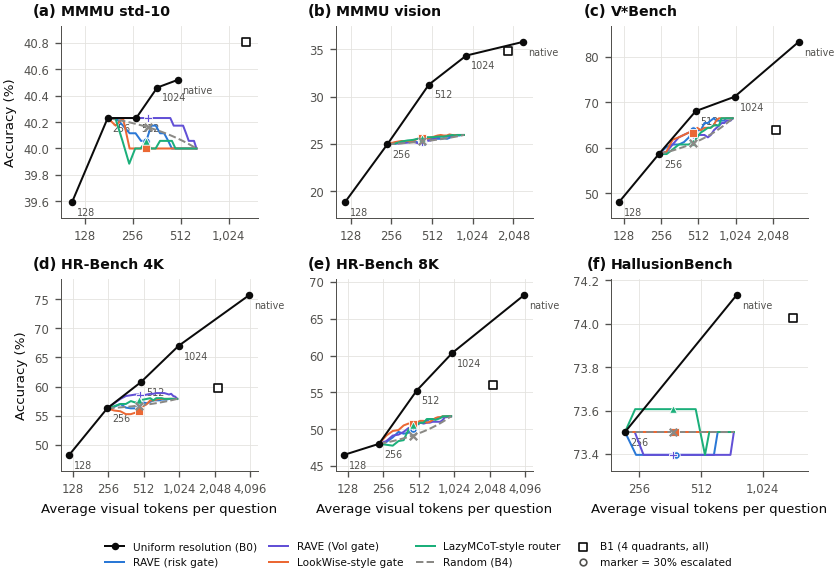

⏱ P7.F1 frontiers | wall 8.55 s | CPU 8.45 s (0.99 cores, sys 74.8%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
figure -> /content/rave_work/figures/fig_final_2_consistency.pdf


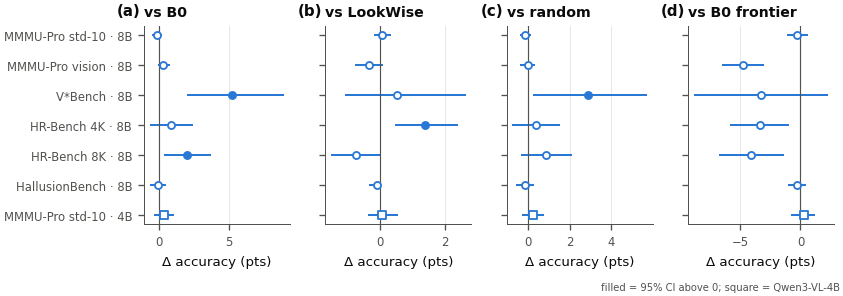

⏱ P7.F2 consistency forest | wall 2.97 s | CPU 2.97 s (1.0 cores, sys 66.3%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
figure -> /content/rave_work/figures/fig_final_3_gates.pdf


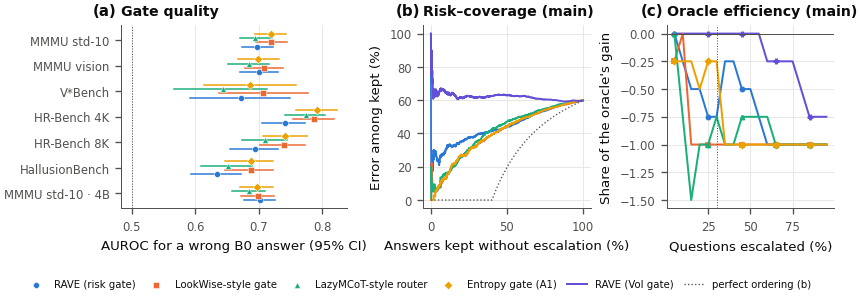

⏱ P7.F3 gate quality | wall 3.01 s | CPU 2.99 s (0.99 cores, sys 56.1%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
figure -> /content/rave_work/figures/fig_final_4_rescued_harmed.pdf


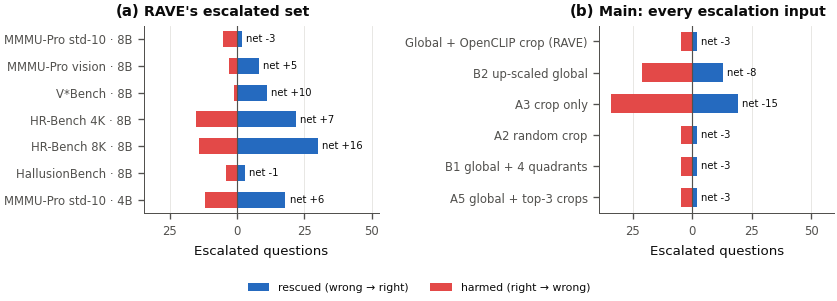

⏱ P7.F4 rescued vs harmed | wall 2.88 s | CPU 2.75 s (0.96 cores, sys 96.1%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
figure -> /content/rave_work/figures/fig_final_5_mechanism.pdf


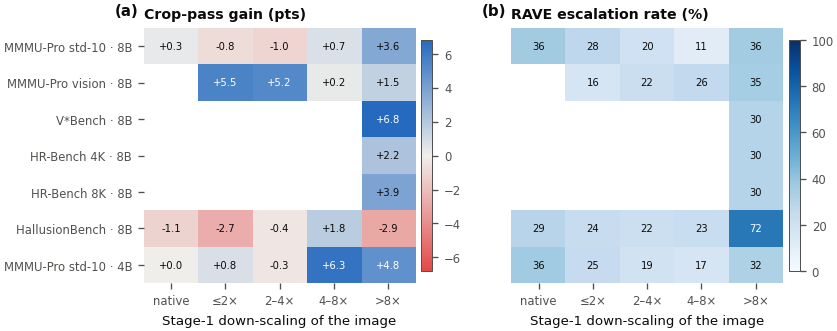

⏱ P7.F5 mechanism heat maps | wall 3.56 s | CPU 3.36 s (0.94 cores, sys 84.3%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
figure -> /content/rave_work/figures/fig_final_6_calibration.pdf


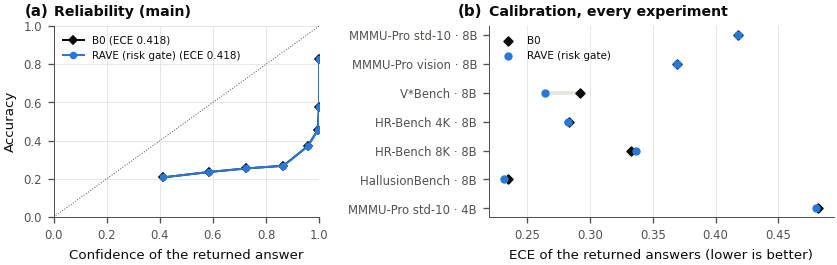

⏱ P7.F6 answer calibration | wall 2.47 s | CPU 2.47 s (1.0 cores, sys 59.4%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


/tmp/ipykernel_1557/262357140.py:175: UserWarning: You passed a edgecolor/edgecolors ('#2a78d6') for an unfilled marker ('|').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter([r_.mean_ms], [yv], color="white", edgecolor=col, marker="|", s=40, zorder=3)
/tmp/ipykernel_1557/262357140.py:175: UserWarning: You passed a edgecolor/edgecolors ('#eb6834') for an unfilled marker ('|').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter([r_.mean_ms], [yv], color="white", edgecolor=col, marker="|", s=40, zorder=3)
/tmp/ipykernel_1557/262357140.py:175: UserWarning: You passed a edgecolor/edgecolors ('#0b0b0b') for an unfilled marker ('|').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter([r_.mean_ms], [yv], color="white", edgecolor=col, marker="|", s=40, zorder=3)


figure -> /content/rave_work/figures/fig_final_7_efficiency.pdf


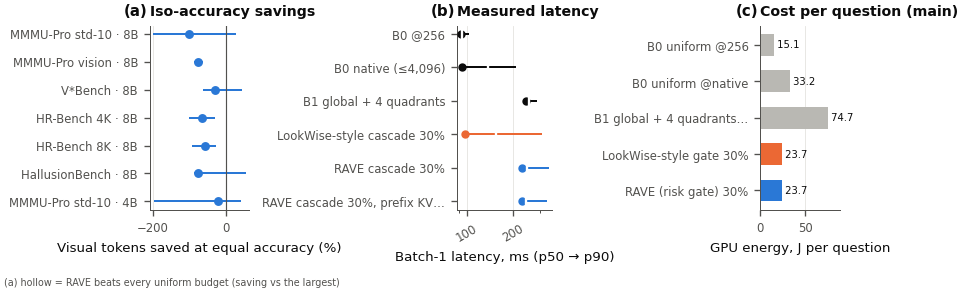

⏱ P7.F7 efficiency | wall 2.78 s | CPU 2.80 s (1.01 cores, sys 57.9%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
figure -> /content/rave_work/figures/fig_final_8_compute.pdf


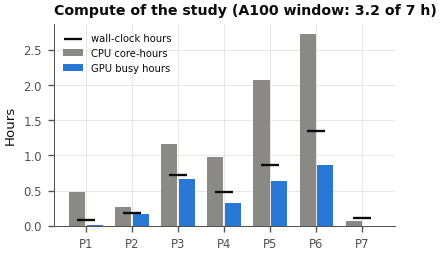

⏱ P7.F8 compute report | wall 1.73 s | CPU 1.74 s (1.01 cores, sys 58.3%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB
⏱ cell 13: SHORT = {k: EXP[k]["name"].replace(" · 8B", "").replace("MMM | wall 28.03 s | CPU 27.61 s (0.99 cores, sys 68.5%) | GPU 0.00 s (no GPU used) | RAM peak 2 GB


In [15]:
SHORT = {k: EXP[k]["name"].replace(" · 8B", "").replace("MMMU-Pro ", "MMMU ") for k in KEYS}
K8 = [k for k in KEYS if EXP[k]["model"] == "8B"]

with Phase("P7.F1 frontiers", budget_min=3):
    n = len(K8); nc = 3 if n > 2 else n; nr = int(np.ceil(n / nc))
    fig, axs = plt.subplots(nr, nc, figsize=(COL2, 2.15 * nr + 0.55), squeeze=False)
    for j, k in enumerate(K8):
        ax = axs[j // nc, j % nc]
        plot_frontier(ax, RR[k], SHORT[k])
        if j % nc == 0:
            ax.set_ylabel("Accuracy (%)")
        if j // nc < nr - 1:
            ax.set_xlabel("")
        panel(ax, "abcdefgh"[j])
    for j in range(n, nr * nc):
        axs[j // nc, j % nc].axis("off")
    fig.tight_layout(rect=(0, 0.07, 1, 1), h_pad=1.0, w_pad=1.0)
    frontier_legend(fig, axs[0, 0], ncol=4, y=0.065)
    save_fig(fig, "fig_final_1_frontiers")

with Phase("P7.F2 consistency forest", budget_min=3):
    cols = [("H0", "vs B0"), ("H1", "vs LookWise"), ("H2", "vs random"), ("H7", "vs B0 frontier")]
    fig, axs = plt.subplots(1, len(cols), figsize=(COL2, 0.22 * len(KEYS) + 1.0), sharey=True)
    ys = np.arange(len(KEYS))[::-1]
    for ax, (h, ttl) in zip(axs, cols):
        for yv, k in zip(ys, KEYS):
            t = RR[k]["tests"].get(h)
            if not t:
                continue
            sig = t["ci_lo"] > 0
            mk = "s" if EXP[k]["model"] == "4B" else "o"
            ax.plot([t["ci_lo"], t["ci_hi"]], [yv, yv], color=COLORS["RAVE_risk"], lw=1.2)
            ax.scatter([t["diff_pts"]], [yv], s=18, marker=mk, zorder=3, color=COLORS["RAVE_risk"] if sig else "white",
                       edgecolor=COLORS["RAVE_risk"], linewidth=1.1)
        ax.axvline(0, color=INK2, lw=0.7)
        ax.set_title(ttl); ax.grid(axis="y", visible=False); ax.set_xlabel("Δ accuracy (pts)")
    axs[0].set_yticks(ys, [EXP[k]["name"] for k in KEYS])
    for j, ax in enumerate(axs):
        panel(ax, "abcd"[j])
    fig.text(0.99, 0.005, "filled = 95% CI above 0; square = Qwen3-VL-4B", ha="right", fontsize=6, color=INK2)
    fig.tight_layout(rect=(0, 0.03, 1, 1), w_pad=0.6)
    save_fig(fig, "fig_final_2_consistency")

with Phase("P7.F3 gate quality", budget_min=3):
    fig, axs = plt.subplots(1, 3, figsize=(COL2, 2.6), gridspec_kw=dict(width_ratios=[1.35, 1, 1]))
    ax = axs[0]; gates = ["RAVE_risk", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy"]
    ys = np.arange(len(KEYS))[::-1]
    for i, gname in enumerate(gates):
        off = (i - 1.5) * 0.17
        for yv, k in zip(ys, KEYS):
            r_ = MXX[k]["gates"].set_index("gate")
            if gname in r_.index and np.isfinite(r_.loc[gname, "AUROC"]):
                ax.plot([r_.loc[gname, "AUROC_lo"], r_.loc[gname, "AUROC_hi"]], [yv + off] * 2, color=COLORS[gname], lw=0.9)
                ax.scatter([r_.loc[gname, "AUROC"]], [yv + off], color=COLORS[gname], marker=MARKERS[gname], s=13, zorder=3,
                           label=NAMES[gname] if yv == ys[0] else None, edgecolor="white", linewidth=0.3)
    ax.axvline(0.5, color=INK2, lw=0.6, ls=":")
    ax.set_yticks(ys, [SHORT[k] if EXP[k]["model"] == "8B" else EXP[k]["name"].replace("MMMU-Pro ", "MMMU ") for k in KEYS])
    ax.grid(axis="y", visible=False); ax.set_xlabel("AUROC for a wrong B0 answer (95% CI)"); ax.set_title("Gate quality")
    panel(ax, "a")
    R = RR["mmmu_std_8b"]; EVm = R["EV"]; y = 1 - EVm.RES[B]["global"]["correct"]
    ax = axs[1]
    for gname in gates + ["RAVE_VoI"]:
        if gname in R["S"]:
            o = np.argsort(R["S"][gname], kind="stable"); e = y[o]
            ax.plot(100 * np.arange(1, len(e) + 1) / len(e), 100 * np.cumsum(e) / np.arange(1, len(e) + 1), color=COLORS[gname], lw=1.1)
    o = np.argsort(y, kind="stable"); e = y[o]
    ax.plot(100 * np.arange(1, len(e) + 1) / len(e), 100 * np.cumsum(e) / np.arange(1, len(e) + 1), color=INK2, lw=0.8, ls=":")
    ax.set_xlabel("Answers kept without escalation (%)"); ax.set_ylabel("Error among kept (%)"); ax.set_title("Risk–coverage (main)")
    panel(ax, "b")
    ax = axs[2]; cv = R["curves"]; b0a = EVm.RES[B]["global"]["correct"].mean()
    orc = cv[cv.policy == "Oracle"].set_index("rate").acc
    for gname in ["RAVE_risk", "RAVE_VoI", "LookWise_conf", "LazyMCoT_GBDT", "A1_entropy"]:
        c_ = cv[cv.policy == gname].set_index("rate").acc
        if len(c_):
            r_ = [r for r in c_.index if 0 < r < 1 and orc[r] > b0a]
            ax.plot([100 * r for r in r_], [(c_[r] - b0a) / (orc[r] - b0a) for r in r_], color=COLORS[gname], lw=1.2,
                    marker=MARKERS[gname], ms=2.5, markevery=4)
    ax.axhline(0, color=INK2, lw=0.6); ax.axvline(100 * MAIN_RATE, color=INK2, lw=0.6, ls=":")
    ax.set_xlabel("Questions escalated (%)"); ax.set_ylabel("Share of the oracle's gain"); ax.set_title("Oracle efficiency (main)")
    panel(ax, "c")
    h_, l_ = axs[0].get_legend_handles_labels()
    h_.append(Line2D([], [], color=COLORS["RAVE_VoI"], lw=1.2)); l_.append(NAMES["RAVE_VoI"])
    h_.append(Line2D([], [], color=INK2, lw=0.8, ls=":")); l_.append("perfect ordering (b)")
    fig.tight_layout(rect=(0, 0.1, 1, 1), w_pad=1.0)
    fig.legend(h_, l_, loc="upper center", ncol=6, bbox_to_anchor=(0.5, 0.09), fontsize=6.1, columnspacing=1.0)
    save_fig(fig, "fig_final_3_gates")

with Phase("P7.F4 rescued vs harmed", budget_min=3):
    fig, axs = plt.subplots(1, 2, figsize=(COL2, 0.24 * max(len(KEYS), 7) + 0.9))
    o_all = pd.DataFrame([dict(input=EXP[k]["name"], **MXX[k]["outcomes"].set_index("kind").loc["joint_top1"].drop("input").to_dict())
                          for k in KEYS])
    for c_ in ("rescued", "harmed", "net", "n"):
        o_all[c_] = o_all[c_].astype(int)
    plot_flips(axs[0], o_all); axs[0].set_title("RAVE's escalated set"); panel(axs[0], "a")
    plot_flips(axs[1], MXX["mmmu_std_8b"]["outcomes"]); axs[1].set_title("Main: every escalation input"); panel(axs[1], "b")
    h_, l_ = axs[0].get_legend_handles_labels()
    fig.tight_layout(rect=(0, 0.08, 1, 1), w_pad=2)
    fig.legend(h_, l_, loc="upper center", ncol=2, bbox_to_anchor=(0.5, 0.075), fontsize=6.5)
    save_fig(fig, "fig_final_4_rescued_harmed")

with Phase("P7.F5 mechanism heat maps", budget_min=3):
    bins = ["native", "≤2×", "2–4×", "4–8×", ">8×"]
    G_ = np.full((len(KEYS), len(bins)), np.nan); E_ = np.full_like(G_, np.nan); N_ = np.zeros_like(G_)
    for i, k in enumerate(KEYS):
        d_ = MXX[k]["downscale"].set_index("bin")
        for j, b_ in enumerate(bins):
            if b_ in d_.index:
                G_[i, j], E_[i, j], N_[i, j] = d_.loc[b_, "crop_gain"], d_.loc[b_, "esc_rate"], d_.loc[b_, "n"]
    keep = ~np.all(np.isnan(G_), axis=0)
    fig, axs = plt.subplots(1, 2, figsize=(COL2, 0.25 * len(KEYS) + 1.2))
    im = plot_heat(axs[0], G_[:, keep], [EXP[k]["name"] for k in KEYS], [b for b, kk in zip(bins, keep) if kk])
    axs[0].set_title("Crop-pass gain (pts)"); axs[0].set_xlabel("Stage-1 down-scaling of the image")
    fig.colorbar(im, ax=axs[0], fraction=0.04, pad=0.02)
    E2 = E_[:, keep]
    im2 = axs[1].imshow(np.ma.masked_invalid(E2), cmap="Blues", vmin=0, vmax=100, aspect="auto")
    for i in range(E2.shape[0]):
        for j in range(E2.shape[1]):
            if np.isfinite(E2[i, j]):
                axs[1].text(j, i, f"{E2[i, j]:.0f}", ha="center", va="center", fontsize=6, color="white" if E2[i, j] > 60 else INK)
    axs[1].set_xticks(range(E2.shape[1]), [b for b, kk in zip(bins, keep) if kk]); axs[1].set_yticks([]); axs[1].grid(False)
    for sp in axs[1].spines.values():
        sp.set_visible(False)
    axs[1].set_title(f"RAVE escalation rate (%)"); axs[1].set_xlabel("Stage-1 down-scaling of the image")
    fig.colorbar(im2, ax=axs[1], fraction=0.04, pad=0.02)
    panel(axs[0], "a"); panel(axs[1], "b")
    fig.tight_layout(w_pad=1.5)
    save_fig(fig, "fig_final_5_mechanism")

with Phase("P7.F6 answer calibration", budget_min=3):
    fig, axs = plt.subplots(1, 2, figsize=(COL2, 2.4), gridspec_kw=dict(width_ratios=[1, 1.3]))
    R = RR["mmmu_std_8b"]; EVm = R["EV"]
    ax = axs[0]
    for lab, Em, col, mk in (("B0", np.zeros(EVm.N, bool), INK, "D"), (NAMES["RAVE_risk"], R["E"], COLORS["RAVE_risk"], "o")):
        P_ = final_distribution(EVm, B, Em); conf = P_.max(1); corr = (P_.argmax(1) == EVm.ans).astype(float)
        edges = np.quantile(conf, np.linspace(0, 1, 9)); edges[-1] += 1e-9
        idx = np.clip(np.digitize(conf, edges) - 1, 0, 7)
        xs = [conf[idx == b_].mean() for b_ in range(8) if (idx == b_).sum() >= 3]
        ys_ = [corr[idx == b_].mean() for b_ in range(8) if (idx == b_).sum() >= 3]
        ax.plot(xs, ys_, color=col, marker=mk, ms=3.5, lw=1.2, label=f"{lab} (ECE {ece(corr, conf):.3f})")
    ax.plot([0, 1], [0, 1], color=INK2, lw=0.6, ls=":"); ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.set_xlabel("Confidence of the returned answer"); ax.set_ylabel("Accuracy"); ax.set_title("Reliability (main)")
    ax.legend(fontsize=6.2, loc="upper left"); panel(ax, "a")
    ax = axs[1]; ys = np.arange(len(KEYS))[::-1]
    for yv, k in zip(ys, KEYS):
        c_ = MXX[k]["calibration"].set_index("policy")
        a_, b_ = c_.loc["B0", "ECE"], c_.loc["RAVE", "ECE"]
        ax.plot([a_, b_], [yv, yv], color=GRID_C, lw=2.2, solid_capstyle="round", zorder=1)
        ax.scatter([a_], [yv], color=INK, marker="D", s=14, zorder=2, label="B0" if yv == ys[0] else None)
        ax.scatter([b_], [yv], color=COLORS["RAVE_risk"], s=16, zorder=3, label=NAMES["RAVE_risk"] if yv == ys[0] else None)
    ax.set_yticks(ys, [EXP[k]["name"] for k in KEYS]); ax.grid(axis="y", visible=False)
    ax.set_xlabel("ECE of the returned answers (lower is better)"); ax.set_title("Calibration, every experiment")
    ax.legend(fontsize=6.2, loc="best"); panel(ax, "b")
    fig.tight_layout(w_pad=1.5)
    save_fig(fig, "fig_final_6_calibration")

with Phase("P7.F7 efficiency", budget_min=3):
    fig, axs = plt.subplots(1, 3, figsize=(COL2, 2.5), gridspec_kw=dict(width_ratios=[1.25, 1.2, 1]))
    ax = axs[0]; rows_ = [(EXP[k]["name"], MXX[k]["tradeoff"]["iso"].get("RAVE_risk")) for k in KEYS]
    rows_ = [(n_, v) for n_, v in rows_ if v]
    ys = np.arange(len(rows_))[::-1]
    for yv, (n_, v) in zip(ys, rows_):
        ax.plot([100 * v["lo"], 100 * v["hi"]], [yv, yv], color=COLORS["RAVE_risk"], lw=1.2)
        ax.scatter([100 * v["savings"]], [yv], s=18, zorder=3, color="white" if v["exceeds"] else COLORS["RAVE_risk"],
                   edgecolor=COLORS["RAVE_risk"], linewidth=1.1)
    ax.axvline(0, color=INK2, lw=0.7)
    ax.set_yticks(ys, [n_ for n_, _ in rows_]); ax.grid(axis="y", visible=False)
    ax.set_xlabel("Visual tokens saved at equal accuracy (%)"); ax.set_title("Iso-accuracy savings"); panel(ax, "a")
    ax = axs[1]
    if LAT_S is not None:
        L_ = LAT_S.iloc[::-1].reset_index(drop=True)
        for yv, r_ in L_.iterrows():
            col = COLORS["RAVE_risk"] if r_.config.startswith("RAVE") else (COLORS["LookWise_conf"] if r_.config.startswith("LookWise") else INK)
            ax.plot([r_.p50_ms, r_.p90_ms], [yv, yv], color=col, lw=1.2)
            ax.scatter([r_.p50_ms], [yv], color=col, s=16, zorder=3)
            ax.scatter([r_.mean_ms], [yv], color="white", edgecolor=col, marker="|", s=40, zorder=3)
        ax.set_yticks(range(len(L_)), [textwrap.shorten(c_, 30, placeholder="…") for c_ in L_.config]); ax.grid(axis="y", visible=False)
        ax.set_xscale("log"); ax.set_xlabel("Batch-1 latency, ms (p50 → p90)"); ax.set_title("Measured latency")
        from matplotlib.ticker import LogLocator, NullFormatter, FuncFormatter
        ax.xaxis.set_major_locator(LogLocator(base=10, subs=(1.0, 2.0, 5.0), numticks=8))
        ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}")); ax.xaxis.set_minor_formatter(NullFormatter())
        ax.tick_params(axis="x", labelrotation=30)
    else:
        ax.text(0.5, 0.5, "run Portion 6\nfor latency", ha="center", va="center", transform=ax.transAxes); ax.set_axis_off()
    panel(ax, "b")
    ax = axs[2]; mm = MXX["mmmu_std_8b"]["methods"]
    sel = mm[mm.method.isin([f"B0 uniform @{B}", "B0 uniform @native", "B1 global + 4 quadrants (all)",
                             f"{NAMES['LookWise_conf']} {int(MAIN_RATE * 100)}%", f"{NAMES['RAVE_risk']} {int(MAIN_RATE * 100)}%"])]
    val = sel.energy_J if sel.energy_J.notna().any() else sel.compute_ms
    unit = "GPU energy, J per question" if sel.energy_J.notna().any() else "Model compute, ms per question"
    ys = np.arange(len(sel))[::-1]
    ax.barh(ys, val.values, height=0.6, color=[COLORS["RAVE_risk"] if s_.startswith("RAVE") else (COLORS["LookWise_conf"] if s_.startswith("LookWise") else "#b9b8b3") for s_ in sel.method])
    for yv, v in zip(ys, val.values):
        ax.text(v, yv, f" {v:.1f}" if v < 100 else f" {v:.0f}", va="center", fontsize=6, color=INK)
    ax.set_yticks(ys, [textwrap.shorten(s_, 24, placeholder="…") for s_ in sel.method]); ax.grid(axis="y", visible=False)
    ax.set_xlabel(unit); ax.set_title("Cost per question (main)"); ax.margins(x=0.18); panel(ax, "c")
    fig.text(0.01, 0.005, "(a) hollow = RAVE beats every uniform budget (saving vs the largest)", fontsize=5.8, color=INK2)
    fig.tight_layout(rect=(0, 0.03, 1, 1), w_pad=1.0)
    save_fig(fig, "fig_final_7_efficiency")

with Phase("P7.F8 compute report", budget_min=2):
    fig, ax = plt.subplots(figsize=(COL1, 2.3))
    xs = np.arange(len(T6)); bw = 0.38
    ax.bar(xs - bw / 2, T6["CPU core-h"], width=bw * 0.92, color="#8a8985", label="CPU core-hours")
    ax.bar(xs + bw / 2, T6["GPU busy h"], width=bw * 0.92, color=COLORS["RAVE_risk"], label="GPU busy hours")
    ax.scatter(xs, T6["Wall h"], color=INK, marker="_", s=120, zorder=3, label="wall-clock hours")
    ax.set_xticks(xs, T6.Portion); ax.set_ylabel("Hours")
    used = sum(T6["A100 window h"])
    ax.set_title(f"Compute of the study (A100 window: {used:.1f} of {WINDOW_H:.0f} h)")
    ax.legend(fontsize=6, loc="upper left")
    fig.tight_layout()
    save_fig(fig, "fig_final_8_compute")

## 5 · Headline numbers, `results_final.json`, save to Drive

In [16]:
R = RR["mmmu_std_8b"]; t = R["tests"]; mx = MXX["mmmu_std_8b"]
iso = mx["tradeoff"]["iso"].get("RAVE_risk")
mm = mx["methods"].set_index("method")
rv = mm.loc[f"{NAMES['RAVE_risk']} {int(MAIN_RATE * 100)}%"]
lines = [f"Main (MMMU-Pro standard-10, {MODEL_ID.split('/')[-1]}, n={R['EV'].N}): RAVE {rv.acc:.1f}% vs B0@{B} "
         f"{mm.loc[f'B0 uniform @{B}'].acc:.1f}% (Δ {t['H0']['diff_pts']:+.1f} pts [{t['H0']['ci_lo']:+.1f}, {t['H0']['ci_hi']:+.1f}]); "
         f"vs LookWise-style {t['H1']['diff_pts']:+.1f} [{t['H1']['ci_lo']:+.1f}, {t['H1']['ci_hi']:+.1f}] (Holm p={t['H1'].get('p_holm', float('nan')):.3f}); "
         f"vs random {t['H2']['diff_pts']:+.1f}."]
if "H7" in t:
    lines.append(f"Above the uniform-resolution frontier at equal tokens: {t['H7']['diff_pts']:+.1f} pts [{t['H7']['ci_lo']:+.1f}, {t['H7']['ci_hi']:+.1f}].")
if iso:
    lines.append(f"Iso-accuracy token saving: {100 * iso['savings']:.0f}% [{100 * iso['lo']:.0f}, {100 * iso['hi']:.0f}]"
                 + (" (beats every uniform budget)" if iso["exceeds"] else "") + ".")
if "B0 uniform @native" in mm.index:
    lines.append(f"Visual tokens: {rv.vis_tokens:.0f} per question = {100 * rv.vis_tokens / mm.loc['B0 uniform @native'].vis_tokens:.0f}% of native.")
won = [EXP[k]["name"] for k in KEYS if RR[k]["tests"]["H0"]["ci_lo"] > 0]
lines.append(f"RAVE > B0 with the CI above 0 on {len(won)} of {len(KEYS)} experiments: {', '.join(won) or 'none'}.")
if LAT_S is not None:
    lm = LAT_S.set_index("config")
    lines.append("Batch-1 latency p50: " + "; ".join(f"{c_}: {lm.loc[c_, 'p50_ms']:.0f} ms" for c_ in lm.index))
print("\n".join(lines))
FINAL = dict(created=dt.datetime.now().isoformat(timespec="seconds"), integrity=INTEGRITY, headline=lines,
             experiments={k: dict(name=EXP[k]["name"], n=int(RR[k]["EV"].N), tests=RR[k]["tests"], auc=RR[k]["AUC"],
                                  auc_repeats=RR[k]["auc_repeats"], iso=MXX[k]["tradeoff"]["iso"], auac=MXX[k]["tradeoff"]["auac"],
                                  pareto=MXX[k]["tradeoff"]["pareto"], calibration=MXX[k]["calibration"].to_dict("records"),
                                  outcomes=MXX[k]["outcomes"].to_dict("records")) for k in KEYS},
             compute=T6.to_dict("records"), co2_kg_per_kwh=CO2_KG_PER_KWH,
             tables=sorted(p.name for p in PAPER.glob("*.tex")), figures=sorted(p.name for p in FIG_DIR.glob("fig_final_*.pdf")))
(PAPER / "results_final.json").write_text(json.dumps(FINAL, indent=2, default=float))
print("\ntables:", FINAL["tables"]); print("figures:", FINAL["figures"])
time_report("P7")
sync_to_drive(quiet=False)
save_notebook_copy("RAVE_v4_P7_final_evaluation")

Main (MMMU-Pro standard-10, Qwen3-VL-8B-Instruct, n=1730): RAVE 40.1% vs B0@256 40.2% (Δ -0.2 pts [-0.5, +0.1]); vs LookWise-style +0.1 [-0.2, +0.3] (Holm p=0.846); vs random -0.1.
Above the uniform-resolution frontier at equal tokens: -0.3 pts [-1.1, +0.5].
Iso-accuracy token saving: -101% [-196, 25].
Visual tokens: 312 per question = 64% of native.
RAVE > B0 with the CI above 0 on 2 of 7 experiments: V*Bench · 8B, HR-Bench 8K · 8B.
Batch-1 latency p50: B0 @256: 93 ms; B0 native (≤4,096): 93 ms; B1 global + 4 quadrants: 242 ms; LookWise-style cascade 30%: 97 ms; RAVE cascade 30%: 228 ms; RAVE cascade 30%, prefix KV reuse: 230 ms

tables: ['table1_main.tex', 'table2_generalisation.tex', 'table3_gates.tex', 'table4_outcomes.tex', 'table4b_inputs_main.tex', 'table5_hypotheses.tex', 'table6_compute.tex', 'table7_benchmark_metrics.tex', 'table8_answer_calibration.tex']
figures: ['fig_final_1_frontiers.pdf', 'fig_final_2_consistency.pdf', 'fig_final_3_gates.pdf', 'fig_final_4_rescued_harmed